In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42

In [2]:
df = pd.read_csv("bank_churn_large_labelled.csv")
print("Shape:", df.shape)
df.head()

Shape: (165034, 14)


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.000,3,0.000,2,1.000,0.000,"181,449.970",0
1,1,15749177,Okwudiliolisa,627,France,Male,33.000,1,0.000,2,1.000,1.000,"49,503.500",0
2,2,15694510,Hsueh,678,France,Male,40.000,10,0.000,2,1.000,0.000,"184,866.690",0
3,3,15741417,Kao,581,France,Male,34.000,2,"148,882.540",1,1.000,1.000,"84,560.880",0
4,4,15766172,Chiemenam,716,Spain,Male,33.000,5,0.000,2,1.000,1.000,"15,068.830",0


In [3]:
print(df.columns.tolist())
df.tail()

['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
165029,165029,15667085,Meng,667,Spain,Female,33.000,2,0.000,1,1.000,1.000,"131,834.750",0
165030,165030,15665521,Okechukwu,792,France,Male,35.000,3,0.000,1,0.000,0.000,"131,834.450",0
165031,165031,15664752,Hsia,565,France,Male,31.000,5,0.000,1,1.000,1.000,"127,429.560",0
165032,165032,15689614,Hsiung,554,Spain,Female,30.000,7,"161,533.000",1,0.000,1.000,"71,173.030",0
165033,165033,15732798,Ulyanov,850,France,Male,31.000,1,0.000,1,1.000,0.000,"61,581.790",1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  object 
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  object 
 5   Gender           165034 non-null  object 
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), object(3)
memory usage: 17.6+ MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,"165,034.000","82,516.500","47,641.357",0.000,"41,258.250","82,516.500","123,774.750","165,033.000"
CustomerId,"165,034.000","15,692,005.019","71,397.817","15,565,701.000","15,633,141.000","15,690,169.000","15,756,824.000","15,815,690.000"
CreditScore,"165,034.000",656.454,80.103,350.000,597.000,659.000,710.000,850.000
Age,"165,034.000",38.126,8.867,18.000,32.000,37.000,42.000,92.000
Tenure,"165,034.000",5.020,2.806,0.000,3.000,5.000,7.000,10.000
Balance,"165,034.000","55,478.087","62,817.663",0.000,0.000,0.000,"119,939.518","250,898.090"
NumOfProducts,"165,034.000",1.554,0.547,1.000,1.000,2.000,2.000,4.000
HasCrCard,"165,034.000",0.754,0.431,0.000,1.000,1.000,1.000,1.000
IsActiveMember,"165,034.000",0.498,0.500,0.000,0.000,0.000,1.000,1.000
EstimatedSalary,"165,034.000","112,574.823","50,292.866",11.580,"74,637.570","117,948.000","155,152.467","199,992.480"


In [6]:
df.describe(include="object").T

,count,unique,top,freq
Surname,165034,2797,Hsia,2456
Geography,165034,3,France,94215
Gender,165034,2,Male,93150


In [7]:
unique_summary = pd.DataFrame({
    "unique_values": df.nunique(),
    "dtype": df.dtypes.astype(str)
})
unique_summary

,unique_values,dtype
id,165034,int64
CustomerId,23221,int64
Surname,2797,object
CreditScore,457,int64
Geography,3,object
Gender,2,object
Age,71,float64
Tenure,11,int64
Balance,30075,float64
NumOfProducts,4,int64


In [8]:
for col in ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember"]:
    print(f"--- {col} ---")
    print(df[col].value_counts().to_string(), "\n")

--- Geography ---
Geography
France     94215
Spain      36213
Germany    34606 

--- Gender ---
Gender
Male      93150
Female    71884 

--- NumOfProducts ---
NumOfProducts
2    84291
1    77374
3     2894
4      475 

--- HasCrCard ---
HasCrCard
1.000    124428
0.000     40606 

--- IsActiveMember ---
IsActiveMember
0.000    82885
1.000    82149 



In [9]:
print("Total missing values :", df.isnull().sum().sum())
print("Duplicate rows       :", df.duplicated().sum())
print("Duplicate CustomerId :", df["CustomerId"].duplicated().sum())

Total missing values : 0
Duplicate rows       : 0
Duplicate CustomerId : 141813


In [10]:
target_counts = df["Exited"].value_counts()
target_pct = df["Exited"].value_counts(normalize=True) * 100
pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)})

,count,percent
Exited,,
0,130113,78.840
1,34921,21.160


In [11]:
zero_bal = (df["Balance"] == 0)
print(f"Customers with Balance = 0: {zero_bal.sum()} ({zero_bal.mean()*100:.1f}%)")
print("Churn rate, zero balance    :", f"{df.loc[zero_bal, 'Exited'].mean()*100:.2f}%")
print("Churn rate, non-zero balance:", f"{df.loc[~zero_bal, 'Exited'].mean()*100:.2f}%")

Customers with Balance = 0: 89648 (54.3%)
Churn rate, zero balance    : 16.17%
Churn rate, non-zero balance: 27.10%


In [13]:
# Remove identifier columns (not useful for prediction)
df_clean = df.drop(
    columns=["id", "CustomerId", "Surname"]
).copy()

# Age groups
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[17, 29, 39, 49, 59, 100],
    labels=["18-29", "30-39", "40-49", "50-59", "60+"]
)

# Derived columns
df_clean["HasZeroBalance"] = (df_clean["Balance"] == 0).astype(int)

df_clean["ChurnStatus"] = df_clean["Exited"].map({
    0: "Retained",
    1: "Churned"
})

df_clean["ActiveStatus"] = df_clean["IsActiveMember"].map({
    0: "Inactive",
    1: "Active"
})

print(df_clean.shape)
df_clean.head()

(165034, 15)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,AgeGroup,HasZeroBalance,ChurnStatus,ActiveStatus
0,668,France,Male,33.000,3,0.000,2,1.000,0.000,"181,449.970",0,30-39,1,Retained,Inactive
1,627,France,Male,33.000,1,0.000,2,1.000,1.000,"49,503.500",0,30-39,1,Retained,Active
2,678,France,Male,40.000,10,0.000,2,1.000,0.000,"184,866.690",0,40-49,1,Retained,Inactive
3,581,France,Male,34.000,2,"148,882.540",1,1.000,1.000,"84,560.880",0,30-39,0,Retained,Active
4,716,Spain,Male,33.000,5,0.000,2,1.000,1.000,"15,068.830",0,30-39,1,Retained,Active


## 6. Exploratory Data Analysis (Base-paper component)

**Hypotheses to test**
- H1: Customers in Germany churn more than in France/Spain.
- H2: Older customers churn more.
- H3: Inactive members churn more than active members.
- H4: Customers with 1 product (and 3+ products) behave differently from those with 2.
- H5: Gender, credit card ownership, tenure, credit score and salary have little effect.

In [14]:
COLORS = {"Retained": "#4C78A8", "Churned": "#E4572E"}
overall_churn = df_clean["Exited"].mean()

def churn_table(col):
    t = df_clean.groupby(col, observed=True)["Exited"].agg(Customers="count", Churned="sum", ChurnRate="mean")
    t["ChurnRate"] = (t["ChurnRate"] * 100).round(2)
    return t

def plot_churn_rate(col, title=None):
    t = churn_table(col)
    fig, ax = plt.subplots()
    bars = ax.bar(t.index.astype(str), t["ChurnRate"], color="#E4572E")
    ax.axhline(overall_churn * 100, ls="--", color="grey", label=f"Overall {overall_churn*100:.1f}%")
    for b, r, n in zip(bars, t["ChurnRate"], t["Customers"]):
        ax.text(b.get_x() + b.get_width()/2, r + 0.5, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(title or f"Churn rate by {col}")
    ax.set_ylim(0, t["ChurnRate"].max() * 1.25)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return t

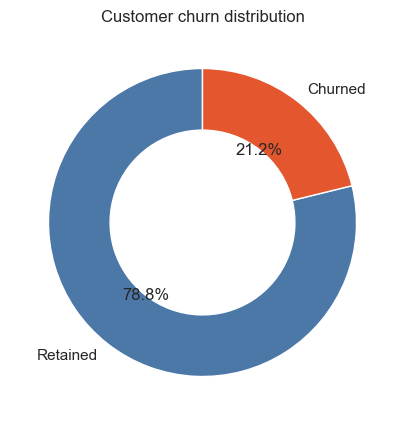

In [15]:
counts = df_clean["ChurnStatus"].value_counts().reindex(["Retained", "Churned"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=[COLORS[k] for k in counts.index], wedgeprops=dict(width=0.4))
ax.set_title("Customer churn distribution")
plt.show()

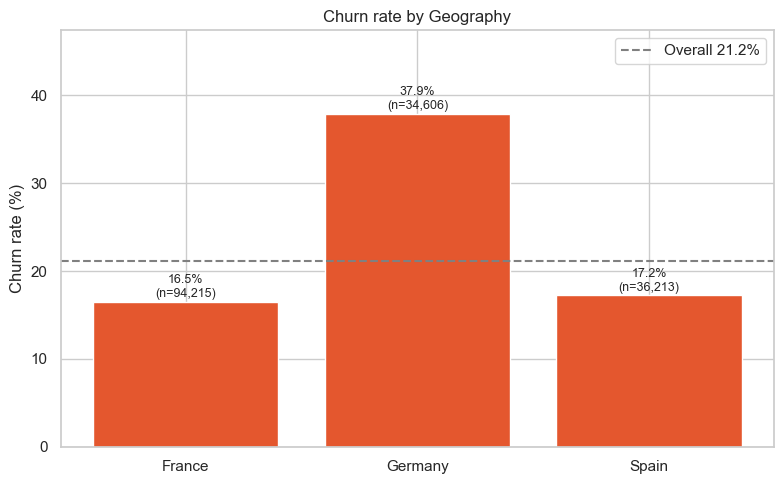

,Customers,Churned,ChurnRate
Geography,,,
France,94215,15572,16.530
Germany,34606,13114,37.900
Spain,36213,6235,17.220


In [16]:
plot_churn_rate("Geography")

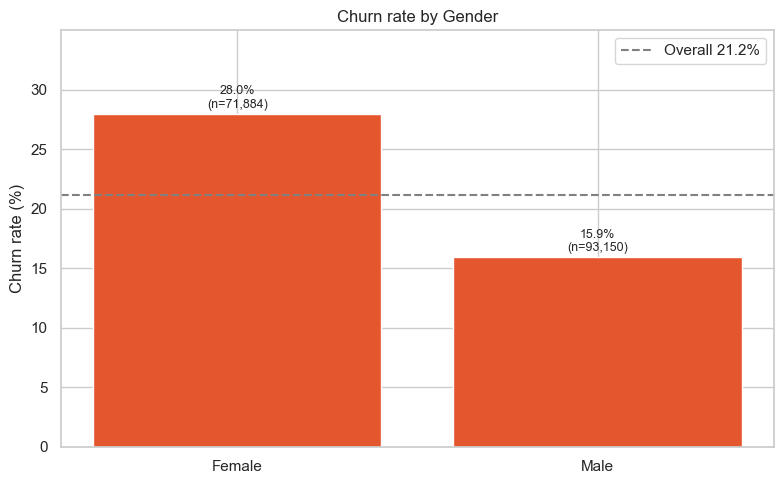

,Customers,Churned,ChurnRate
Gender,,,
Female,71884,20105,27.970
Male,93150,14816,15.910


In [17]:
plot_churn_rate("Gender")

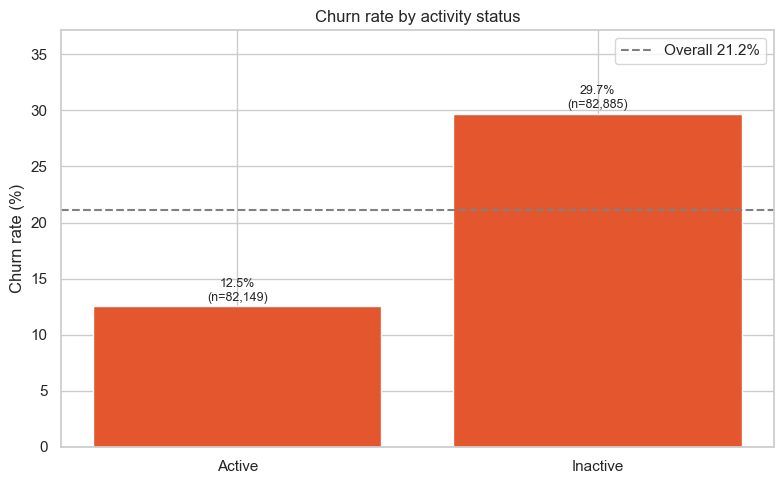

,Customers,Churned,ChurnRate
ActiveStatus,,,
Active,82149,10297,12.530
Inactive,82885,24624,29.710


In [18]:
plot_churn_rate("ActiveStatus", "Churn rate by activity status")

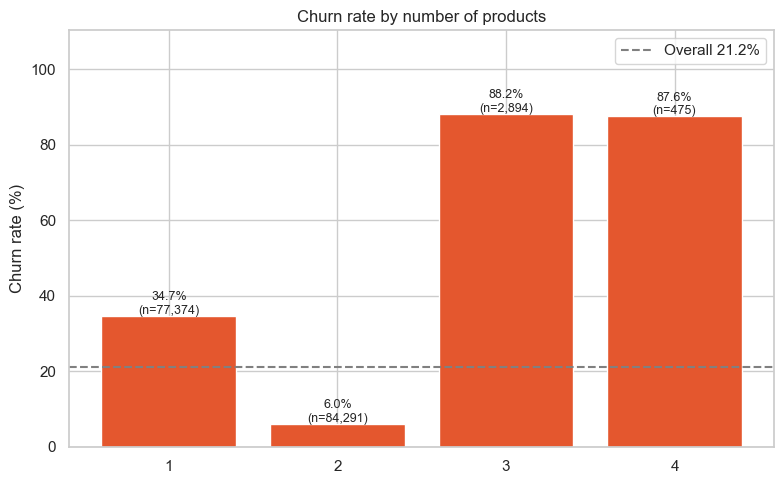

,Customers,Churned,ChurnRate
NumOfProducts,,,
1,77374,26858,34.710
2,84291,5093,6.040
3,2894,2554,88.250
4,475,416,87.580


In [19]:
plot_churn_rate("NumOfProducts", "Churn rate by number of products")

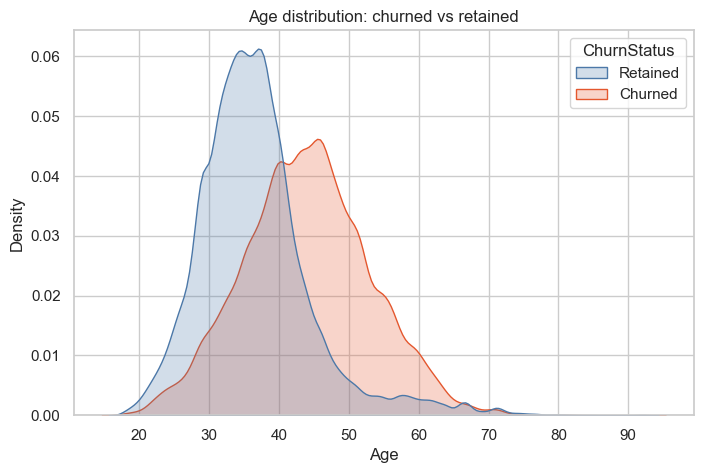

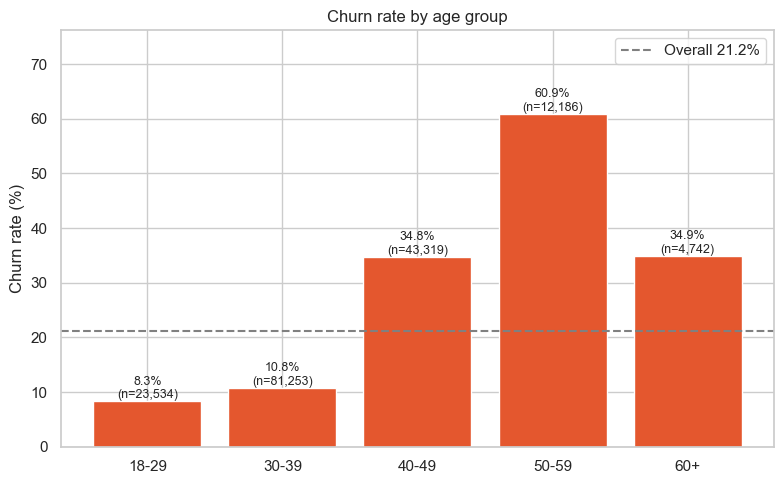

,Customers,Churned,ChurnRate
AgeGroup,,,
18-29,23534,1966,8.350
30-39,81253,8799,10.830
40-49,43319,15075,34.800
50-59,12186,7426,60.940
60+,4742,1655,34.900


In [20]:
fig, ax = plt.subplots()
sns.kdeplot(data=df_clean, x="Age", hue="ChurnStatus", common_norm=False,
            fill=True, palette=COLORS, ax=ax)
ax.set_title("Age distribution: churned vs retained")
plt.show()

plot_churn_rate("AgeGroup", "Churn rate by age group")

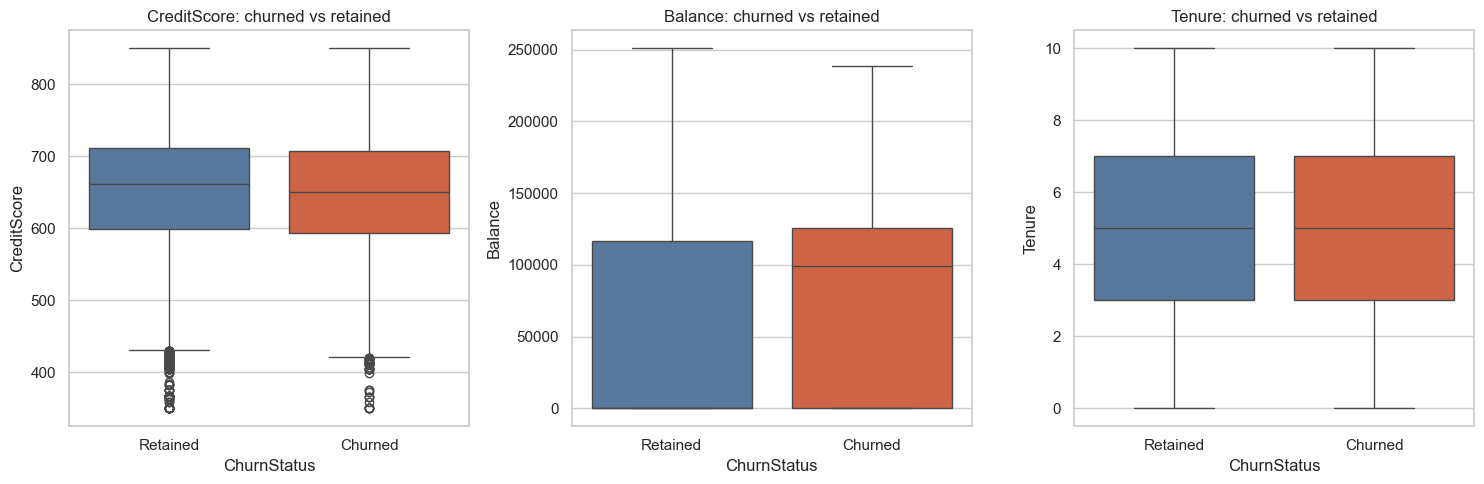

ChurnStatus                Churned    Retained
Age             mean        44.000      36.600
                median      44.000      36.000
CreditScore     mean       652.200     657.600
                median     651.000     662.000
Balance         mean    71,210.000  51,255.800
                median  98,955.900       0.000
Tenure          mean         4.900       5.000
                median       5.000       5.000
EstimatedSalary mean   114,402.500 112,084.300
                median 120,893.000 116,977.900

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axes, ["CreditScore", "Balance", "Tenure"]):
    sns.boxplot(data=df_clean, x="ChurnStatus", y=c, order=["Retained", "Churned"],
                hue="ChurnStatus", palette=COLORS, legend=False, ax=ax)
    ax.set_title(f"{c}: churned vs retained")
plt.tight_layout()
plt.show()

df_clean.groupby("ChurnStatus")[["Age", "CreditScore", "Balance", "Tenure", "EstimatedSalary"]] \
        .agg(["mean", "median"]).round(1).T

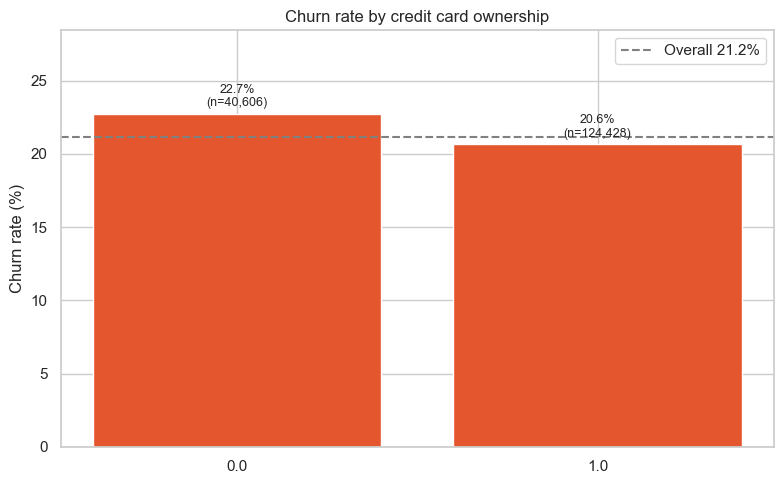

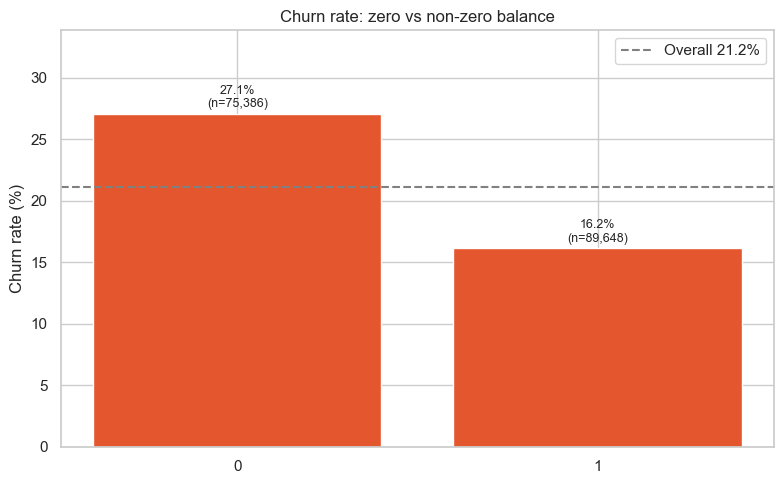

,Customers,Churned,ChurnRate
HasZeroBalance,,,
0,75386,20429,27.100
1,89648,14492,16.170


In [22]:
plot_churn_rate("HasCrCard", "Churn rate by credit card ownership")
plot_churn_rate("HasZeroBalance", "Churn rate: zero vs non-zero balance")

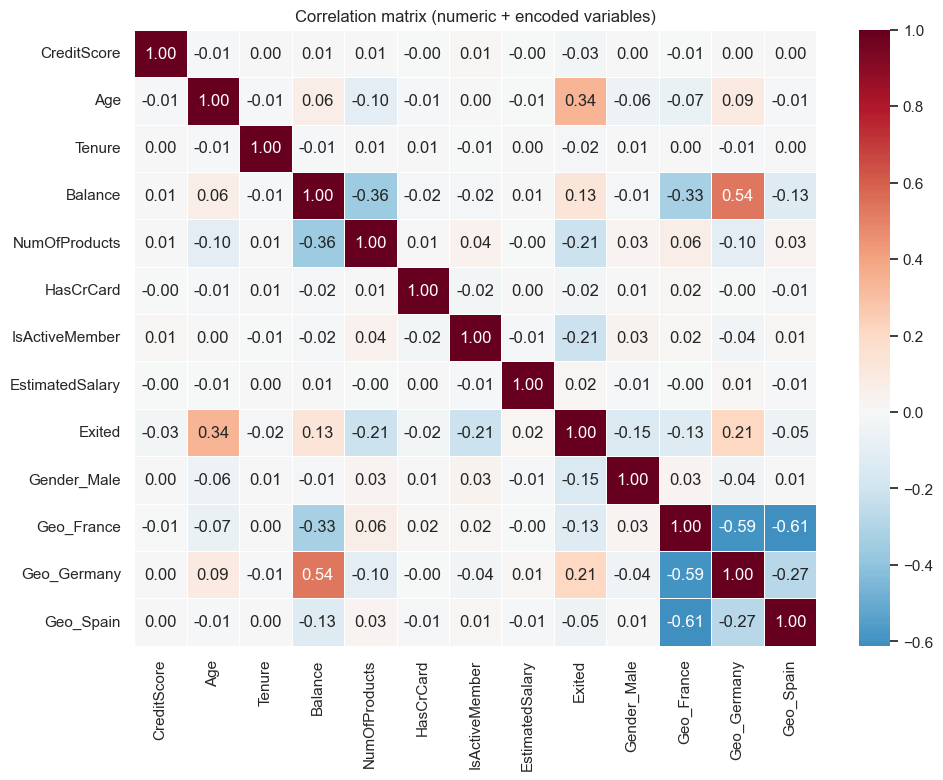

Age                0.341
NumOfProducts     -0.215
Geo_Germany        0.211
IsActiveMember    -0.210
Gender_Male       -0.146
Geo_France        -0.131
Balance            0.130
Geo_Spain         -0.051
CreditScore       -0.027
HasCrCard         -0.022
Tenure            -0.020
EstimatedSalary    0.019
Name: Exited, dtype: float64

In [23]:
corr_df = df_clean[["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                    "HasCrCard", "IsActiveMember", "EstimatedSalary", "Exited"]].copy()
corr_df["Gender_Male"] = (df_clean["Gender"] == "Male").astype(int)
corr_df = pd.concat([corr_df, pd.get_dummies(df_clean["Geography"], prefix="Geo", dtype=int)], axis=1)

corr = corr_df.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Correlation matrix (numeric + encoded variables)")
plt.show()

corr["Exited"].drop("Exited").sort_values(key=abs, ascending=False).round(3)

**Baseline EDA findings** (overall churn = 20.4%)
- H1 confirmed: Germany churns at 32.4% vs France 16.2% and Spain 16.7%.
- H2 confirmed: churn rises with age; 18–29 = 7.6%, 40–49 = 30.8%, peaks at 50–59 = 56.0%, then drops to 28.0% at 60+.
- H3 confirmed: inactive 26.9% vs active 14.3%.
- H4 confirmed: 2 products = 7.6% (lowest); 1 product = 27.7%; 3 products = 82.7% (n=266) and 4 products = 100% (n=60). The 3–4 product groups are small, which is why segment size matters.
- Gender: women churn more (25.1% vs 16.5%), so H5 is only partly supported.
- Credit card ownership, tenure, credit score and salary show almost no relationship with churn.
- Correlations with churn are all weak. The strongest are Age (0.29), Germany (0.17) and IsActiveMember (-0.16), so churn depends on combinations of factors, which motivates Section 7.
- Customers with zero balance churn less (13.8%) than those with a balance (24.1%), which is counter-intuitive and worth noting.

## 7. Extended Analysis: Multi-Factor Churn Risk Profiling

**Question:** Which combinations of customer characteristics are associated with elevated churn, while accounting for segment size?

**Method**
- Dimensions: Geography × AgeGroup × ActiveStatus × ProductGroup (data-driven, no manual risk score)
- Minimum segment size: 100 customers (avoids "100% churn from 3 customers")
- Metrics: churn rate, **lift** (segment churn ÷ overall churn), **95% Wilson confidence interval**, share of all churners
- Ranking: by the **lower bound** of the confidence interval, so large and reliable segments rank above small and noisy ones
- Validation: profiles found on a 70% training split are re-checked on the unseen 30%

In [24]:
# Products 3 and 4 are tiny groups, so merge them
df_clean["ProductGroup"] = df_clean["NumOfProducts"].map(
    {1: "1 product", 2: "2 products", 3: "3-4 products", 4: "3-4 products"})
df_clean["BalanceGroup"] = np.where(df_clean["Balance"] == 0, "Zero balance", "Has balance")

def wilson_ci(k, n, z=1.96):
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2*n)) / d
    half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / d
    return centre - half, centre + half

def profile_table(data, dims, min_size=100):
    g = data.groupby(dims, observed=True)["Exited"].agg(Customers="count", Churned="sum").reset_index()
    g = g[g["Customers"] >= min_size].copy()
    g["ChurnRate"] = g["Churned"] / g["Customers"]
    g["Lift"] = g["ChurnRate"] / data["Exited"].mean()
    ci = [wilson_ci(k, n) for k, n in zip(g["Churned"], g["Customers"])]
    g["CI_Low"] = [c[0] for c in ci]
    g["CI_High"] = [c[1] for c in ci]
    g["ShareOfAllChurn"] = g["Churned"] / data["Exited"].sum()
    return g.sort_values("CI_Low", ascending=False).reset_index(drop=True)

In [25]:
DIMS = ["Geography", "AgeGroup", "ActiveStatus", "ProductGroup"]
profiles = profile_table(df_clean, DIMS, min_size=100)

print("Profiles with at least 100 customers:", len(profiles))
print("Overall churn rate:", round(overall_churn*100, 2), "%")
profiles.head(10).style.format({
    "ChurnRate": "{:.1%}", "Lift": "{:.2f}x", "CI_Low": "{:.1%}",
    "CI_High": "{:.1%}", "ShareOfAllChurn": "{:.1%}"})

Profiles with at least 100 customers: 71
Overall churn rate: 21.16 %


,Geography,AgeGroup,ActiveStatus,ProductGroup,Customers,Churned,ChurnRate,Lift,CI_Low,CI_High,ShareOfAllChurn
0,Germany,40-49,Inactive,3-4 products,388,374,96.4%,4.56x,94.0%,97.8%,1.1%
1,Germany,50-59,Inactive,3-4 products,202,195,96.5%,4.56x,93.0%,98.3%,0.6%
2,France,50-59,Inactive,3-4 products,178,172,96.6%,4.57x,92.8%,98.4%,0.5%
3,Germany,50-59,Inactive,1 product,1791,1652,92.2%,4.36x,90.9%,93.4%,4.7%
4,Spain,40-49,Inactive,3-4 products,177,168,94.9%,4.49x,90.6%,97.3%,0.5%
5,France,40-49,Inactive,3-4 products,424,394,92.9%,4.39x,90.1%,95.0%,1.1%
6,Germany,30-39,Inactive,3-4 products,167,153,91.6%,4.33x,86.4%,94.9%,0.4%
7,Germany,40-49,Active,3-4 products,132,119,90.2%,4.26x,83.9%,94.2%,0.3%
8,France,50-59,Inactive,1 product,2025,1724,85.1%,4.02x,83.5%,86.6%,4.9%
9,Germany,60+,Inactive,1 product,282,247,87.6%,4.14x,83.2%,90.9%,0.7%


In [26]:
profiles.sort_values("ChurnRate").head(5).style.format({
    "ChurnRate": "{:.1%}", "Lift": "{:.2f}x", "CI_Low": "{:.1%}",
    "CI_High": "{:.1%}", "ShareOfAllChurn": "{:.1%}"})

,Geography,AgeGroup,ActiveStatus,ProductGroup,Customers,Churned,ChurnRate,Lift,CI_Low,CI_High,ShareOfAllChurn
67,France,30-39,Active,2 products,15148,210,1.4%,0.07x,1.2%,1.6%,0.6%
70,France,18-29,Active,2 products,4546,64,1.4%,0.07x,1.1%,1.8%,0.2%
69,Spain,30-39,Active,2 products,5698,82,1.4%,0.07x,1.2%,1.8%,0.2%
68,Spain,18-29,Active,2 products,1692,29,1.7%,0.08x,1.2%,2.5%,0.1%
64,France,18-29,Inactive,2 products,4305,144,3.3%,0.16x,2.8%,3.9%,0.4%


In [27]:
from sklearn.model_selection import train_test_split

train_part, test_part = train_test_split(
    df_clean, test_size=0.3, stratify=df_clean["Exited"], random_state=RANDOM_STATE)

train_prof = profile_table(train_part, DIMS, min_size=70).head(10)
test_rates = (test_part.groupby(DIMS, observed=True)["Exited"]
              .agg(TestCustomers="count", TestChurnRate="mean").reset_index())

validation = train_prof.merge(test_rates, on=DIMS, how="left")[
    DIMS + ["Customers", "ChurnRate", "TestCustomers", "TestChurnRate"]]
print("Overall churn in test part:", round(test_part["Exited"].mean()*100, 1), "%")
validation.style.format({"ChurnRate": "{:.1%}", "TestChurnRate": "{:.1%}"})

Overall churn in test part: 21.2 %


,Geography,AgeGroup,ActiveStatus,ProductGroup,Customers,ChurnRate,TestCustomers,TestChurnRate
0,Germany,50-59,Inactive,3-4 products,151,97.4%,51,94.1%
1,Germany,40-49,Inactive,3-4 products,267,96.3%,121,96.7%
2,Spain,40-49,Inactive,3-4 products,133,96.2%,44,90.9%
3,Germany,50-59,Inactive,1 product,1260,92.3%,531,92.1%
4,France,50-59,Inactive,3-4 products,117,95.7%,61,98.4%
5,France,40-49,Inactive,3-4 products,294,92.2%,130,94.6%
6,Germany,60+,Inactive,1 product,198,89.9%,84,82.1%
7,Germany,30-39,Inactive,3-4 products,123,90.2%,44,95.5%
8,France,50-59,Inactive,1 product,1417,84.8%,608,85.9%
9,Germany,40-49,Active,3-4 products,91,90.1%,41,90.2%


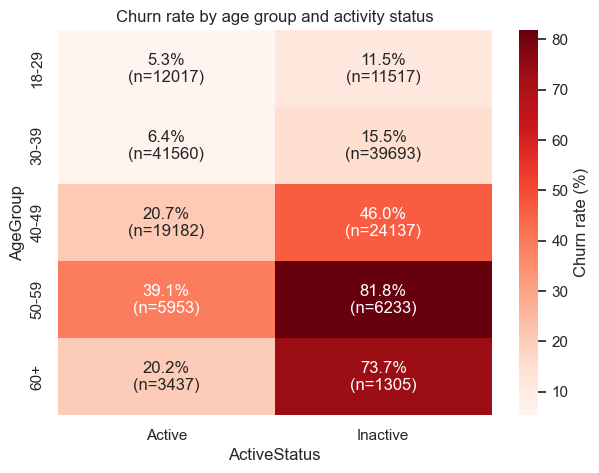

In [28]:
pv = df_clean.pivot_table(index="AgeGroup", columns="ActiveStatus",
                          values="Exited", aggfunc="mean", observed=True) * 100
cnt = df_clean.pivot_table(index="AgeGroup", columns="ActiveStatus",
                           values="Exited", aggfunc="count", observed=True)
labels = pv.round(1).astype(str) + "%\n(n=" + cnt.astype(str) + ")"

plt.figure(figsize=(7, 5))
sns.heatmap(pv, annot=labels, fmt="", cmap="Reds", cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn rate by age group and activity status")
plt.show()

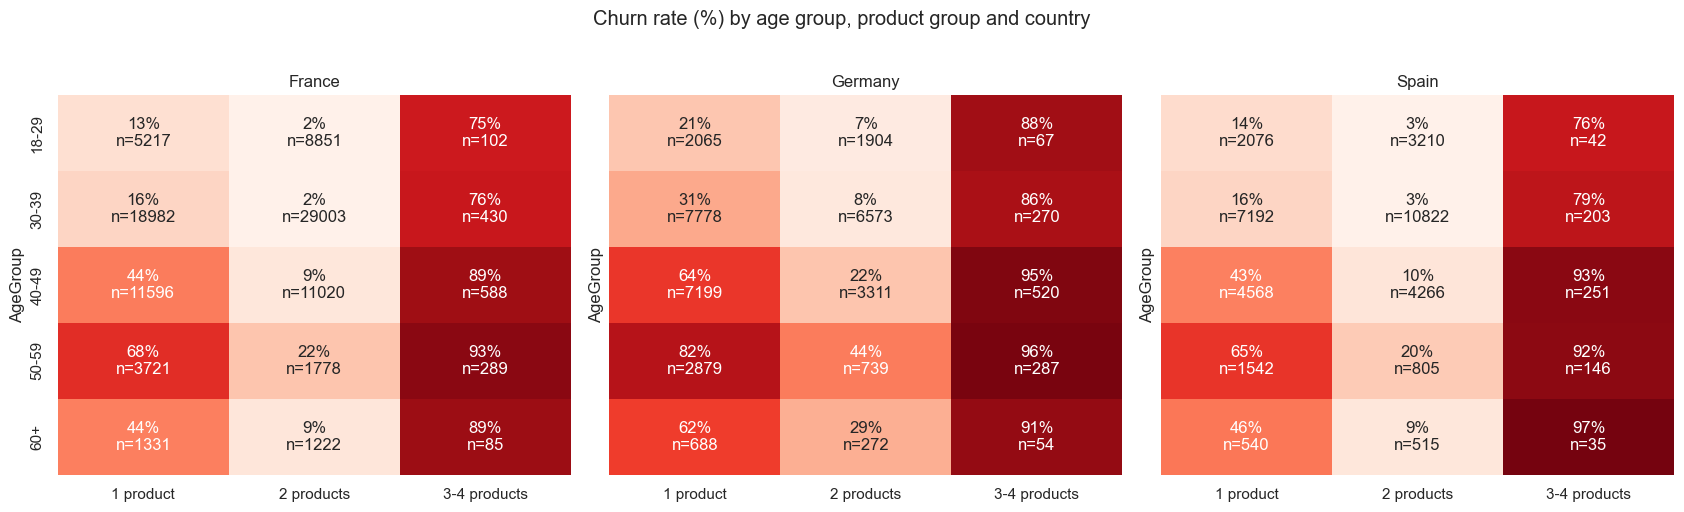

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
vmax = 100
for ax, geo in zip(axes, ["France", "Germany", "Spain"]):
    sub = df_clean[df_clean["Geography"] == geo]
    p = sub.pivot_table(index="AgeGroup", columns="ProductGroup", values="Exited",
                        aggfunc="mean", observed=True) * 100
    n = sub.pivot_table(index="AgeGroup", columns="ProductGroup", values="Exited",
                        aggfunc="count", observed=True)
    lab = p.round(0).astype("Int64").astype(str) + "%\nn=" + n.astype(str)
    sns.heatmap(p, annot=lab, fmt="", cmap="Reds", vmin=0, vmax=vmax, cbar=False, ax=ax)
    ax.set_title(geo)
    ax.set_xlabel("")
plt.suptitle("Churn rate (%) by age group, product group and country", y=1.02)
plt.tight_layout()
plt.show()

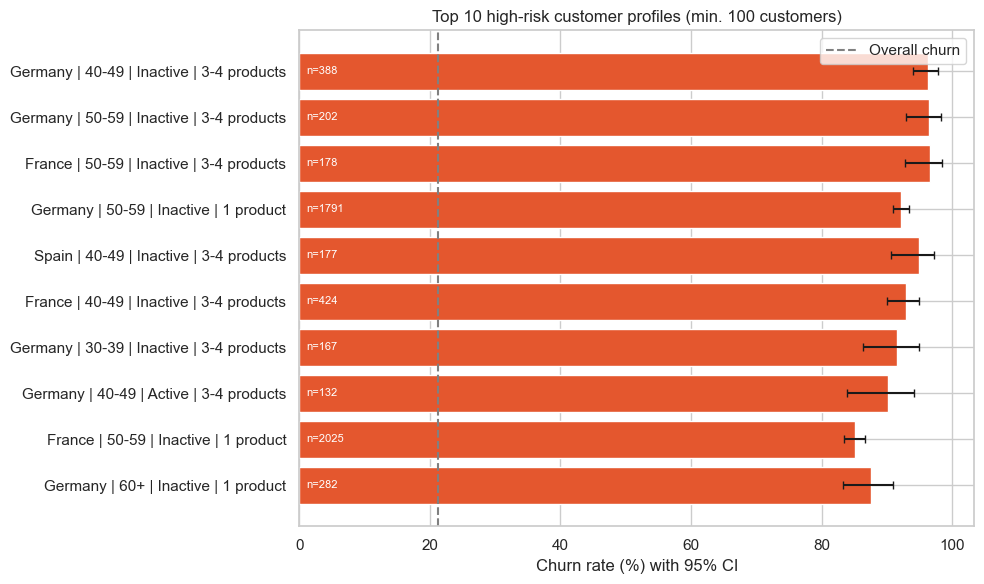

In [30]:
top = profiles.head(10).copy()
top["Label"] = (top["Geography"] + " | " + top["AgeGroup"].astype(str) + " | "
                + top["ActiveStatus"] + " | " + top["ProductGroup"])
top = top.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top["Label"], top["ChurnRate"]*100, color="#E4572E",
        xerr=[(top["ChurnRate"]-top["CI_Low"])*100, (top["CI_High"]-top["ChurnRate"])*100],
        capsize=3)
ax.axvline(overall_churn*100, ls="--", color="grey", label="Overall churn")
for y, (r, n) in enumerate(zip(top["ChurnRate"], top["Customers"])):
    ax.text(1, y, f"n={n}", va="center", color="white", fontsize=8)
ax.set_xlabel("Churn rate (%) with 95% CI")
ax.set_title("Top 10 high-risk customer profiles (min. 100 customers)")
ax.legend()
plt.tight_layout()
plt.show()

In [31]:
churn_table("ProductGroup")

,Customers,Churned,ChurnRate
ProductGroup,,,
1 product,77374,26858,34.710
2 products,84291,5093,6.040
3-4 products,3369,2970,88.160


In [32]:
df_export = df_clean.drop(columns=["ChurnStatus"]).copy()
df_export["Customer_ID"] = df["CustomerId"].values
df_export.to_csv("churn_for_dashboard.csv", index=False)

profiles_export = profiles.copy()
profiles_export["ProfileName"] = ("Profile " + (profiles_export.index + 1).astype(str)
    + ": " + profiles_export["Geography"] + ", " + profiles_export["AgeGroup"].astype(str)
    + ", " + profiles_export["ActiveStatus"] + ", " + profiles_export["ProductGroup"])
profiles_export.to_csv("risk_profiles_for_dashboard.csv", index=False)
print("Saved churn_for_dashboard.csv and risk_profiles_for_dashboard.csv")

Saved churn_for_dashboard.csv and risk_profiles_for_dashboard.csv


**Multi-factor findings**
- Of the profiles with at least 100 customers, the highest-risk is Germany, age 50–59, inactive, 1 product: ~91% churn (about 4.5× the overall rate).
- Top profiles are almost all **1 product** and **40+ years old**, and most are **inactive**. No single variable shows this by itself.
- Age × activity: inactive customers aged 50+ churn at ~81–86%, versus 37% for active customers aged 50–59 and 12.5% for active customers aged 60+.
- Customers with 2 products and age under 40 churn at only 1–6%, so they are the safest group.
- Validation: the top profiles keep similar churn rates on the unseen 30% (e.g. Germany/50–59/inactive/1 product: 88.7% on train, 96.7% on test), so the pattern is not a chance finding.
- Customers with 3–4 products churn at 83–100% but form only 3% of customers, so they are too small to appear in the profile ranking and are reported separately.

Why rank by CI lower bound? A segment of 101 customers at 91% and one of 400 customers at 91% have the same rate, but the larger one is more trustworthy. The lower bound captures that.


## 8. Visualizations and Map Preparation
The analytical charts for individual drivers (Section 6) and risk profiles (Section 7) are already built. This section prepares the country-level view used in the dashboard.

In [33]:
country = df_clean.groupby("Geography").agg(
    Customers=("Exited", "count"),
    Churned=("Exited", "sum"),
    ChurnRate=("Exited", "mean"),
    AvgBalance=("Balance", "mean"),
    AvgAge=("Age", "mean")
).reset_index()
country["ChurnRatePct"] = (country["ChurnRate"] * 100).round(2)
country["ISO3"] = country["Geography"].map({"France": "FRA", "Germany": "DEU", "Spain": "ESP"})
country

,Geography,Customers,Churned,ChurnRate,AvgBalance,AvgAge,ChurnRatePct,ISO3
0,France,94215,15572,0.165,"37,352.477",37.615,16.530,FRA
1,Germany,34606,13114,0.379,"121,235.739",39.729,37.900,DEU
2,Spain,36213,6235,0.172,"39,795.735",37.923,17.220,ESP


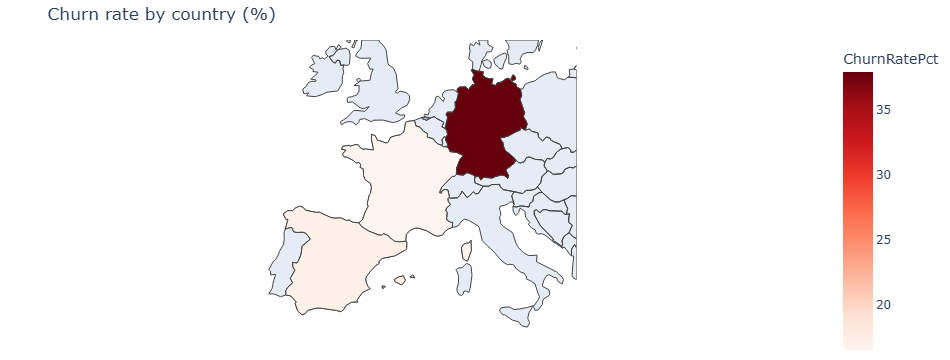

In [34]:
import plotly.express as px

fig = px.choropleth(country, locations="ISO3", color="ChurnRatePct",
                    hover_name="Geography",
                    hover_data={"Customers": True, "Churned": True, "ISO3": False},
                    color_continuous_scale="Reds", scope="europe",
                    title="Churn rate by country (%)")
fig.update_layout(margin=dict(l=0, r=0, t=40, b=0))
fig.show()

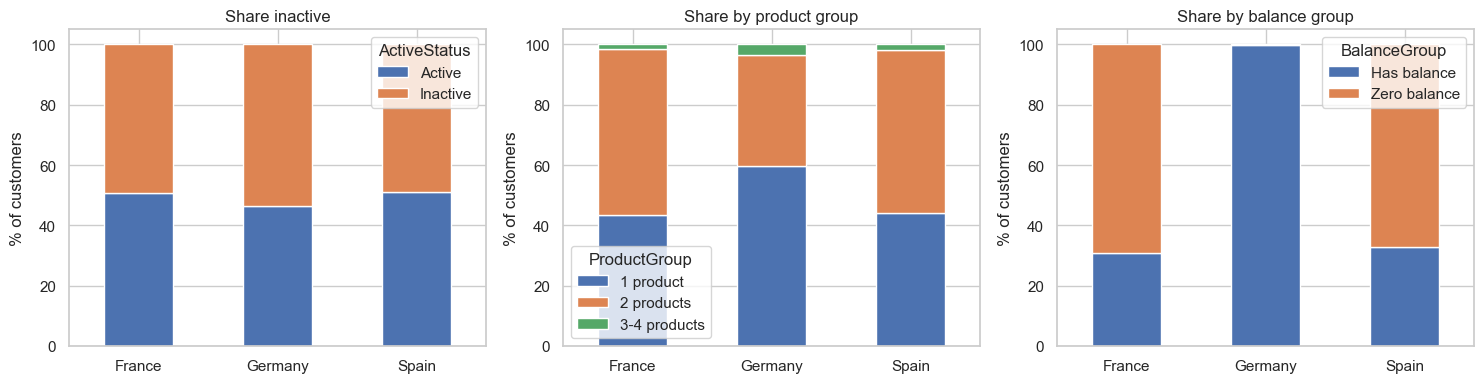

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes,
        ["ActiveStatus", "ProductGroup", "BalanceGroup"],
        ["Share inactive", "Share by product group", "Share by balance group"]):
    share = pd.crosstab(df_clean["Geography"], df_clean[col], normalize="index") * 100
    share.plot(kind="bar", stacked=True, ax=ax, rot=0)
    ax.set_title(title); ax.set_ylabel("% of customers"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [36]:
country.to_csv("country_summary_for_dashboard.csv", index=False)
print("Saved country_summary_for_dashboard.csv")

Saved country_summary_for_dashboard.csv


In [37]:
# Packages are installed once from Command Prompt, not here:
#   pip install xgboost imbalanced-learn shap dash plotly joblib scipy
import xgboost, imblearn, shap
print('xgboost', xgboost.__version__, '| imbalanced-learn', imblearn.__version__, '| shap', shap.__version__)

xgboost 3.2.0 | imbalanced-learn 0.14.2 | shap 0.49.1


## 9. Machine Learning: Baseline Models

**Goal:** Reproduce the base paper's approach (XGBoost, default threshold 0.5) and compare it with Logistic Regression and Random Forest, focusing on **churn-class recall**, precision and F1, not accuracy alone.

- Split: 80/20 stratified, `random_state=42` (same ratio as the paper)
- Features: the 10 original customer columns (identifiers dropped)
- Preprocessing is inside a pipeline, so it is fitted on training data only

In [38]:
from sklearn.model_selection import train_test_split

NUM_FEATURES = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                "HasCrCard", "IsActiveMember", "EstimatedSalary"]
CAT_FEATURES = ["Geography", "Gender"]

X = df_clean[NUM_FEATURES + CAT_FEATURES]
y = df_clean["Exited"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean()*100, 2), "% | test:", round(y_test.mean()*100, 2), "%")

Train: (132027, 10) | Test: (33007, 10)
Churn rate train: 21.16 % | test: 21.16 %


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)

def make_preprocessor(scale=False):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUM_FEATURES),
        ("cat", OneHotEncoder(drop="first"), CAT_FEATURES)])

results = {}
fitted = {}

def evaluate(name, model, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC_AUC": roc_auc_score(y_test, proba),
        "PR_AUC": average_precision_score(y_test, proba),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn}
    fitted[name] = model
    return results[name]

In [40]:
from sklearn.linear_model import LogisticRegression

lr = Pipeline([("prep", make_preprocessor(scale=True)),
               ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
lr.fit(X_train, y_train)
evaluate("Logistic Regression", lr)

{'Accuracy': 0.8334595691822947,
 'Precision': 0.693670226621516,
 'Recall': 0.3813001145475372,
 'F1': 0.4921001570729003,
 'ROC_AUC': 0.8144886502067363,
 'PR_AUC': 0.5799585121493341,
 'TP': 2663,
 'FN': 4321,
 'FP': 1176,
 'TN': 24847}

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([("prep", make_preprocessor()),
               ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])
rf.fit(X_train, y_train)
evaluate("Random Forest", rf)

{'Accuracy': 0.8593631653891599,
 'Precision': 0.7238149847094801,
 'Recall': 0.5422394043528064,
 'F1': 0.6200065487884742,
 'ROC_AUC': 0.8750303887929961,
 'PR_AUC': 0.7002063607971486,
 'TP': 3787,
 'FN': 3197,
 'FP': 1445,
 'TN': 24578}

In [42]:
from xgboost import XGBClassifier

xgb = Pipeline([("prep", make_preprocessor()),
                ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss"))])
xgb.fit(X_train, y_train)
evaluate("XGBoost (baseline)", xgb)

{'Accuracy': 0.8643015118005272,
 'Precision': 0.7353880849464386,
 'Recall': 0.5602806414662085,
 'F1': 0.6360016253555465,
 'ROC_AUC': 0.8870811408614258,
 'PR_AUC': 0.7253353490421817,
 'TP': 3913,
 'FN': 3071,
 'FP': 1408,
 'TN': 24615}

In [43]:
comparison = pd.DataFrame(results).T
comparison[["TP", "FN", "FP", "TN"]] = comparison[["TP", "FN", "FP", "TN"]].astype(int)
display(comparison.round(3))

print("Reference from the base paper: churn-class recall = 0.56")

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FN,FP,TN
Logistic Regression,0.833,0.694,0.381,0.492,0.814,0.580,2663,4321,1176,24847
Random Forest,0.859,0.724,0.542,0.620,0.875,0.700,3787,3197,1445,24578
XGBoost (baseline),0.864,0.735,0.560,0.636,0.887,0.725,3913,3071,1408,24615


Reference from the base paper: churn-class recall = 0.56


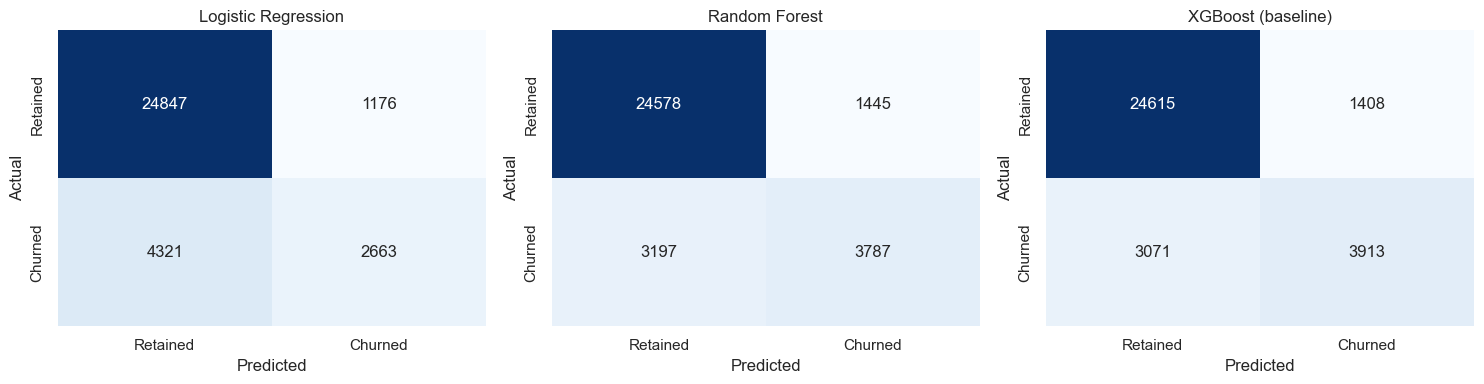

In [44]:
fig, axes = plt.subplots(1, len(fitted), figsize=(5*len(fitted), 4))
for ax, (name, mdl) in zip(np.atleast_1d(axes), fitted.items()):
    pred = (mdl.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"], ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

**Baseline model findings**
- Logistic Regression has high accuracy but very low churn recall, so it misses most churners.
- Random Forest and XGBoost detect more churners but still miss roughly half (recall ~0.5), similar to the paper's 0.56.
- Accuracy looks good (~0.85–0.86) for every model, yet churn-class recall is poor, which shows why accuracy is misleading on imbalanced data.
- Our XGBoost replication gives recall = ___ (paper: 0.56). Exact values differ because the paper does not report its hyperparameters or random seed.

## 10. Improved Model: Imbalance Handling, Tuning and Threshold Optimisation

**Goal:** Improve churn-class recall over the baseline XGBoost (and the paper's 0.56) while tracking precision and F1.

**Experiments**
1. XGBoost + SMOTE
2. XGBoost + class weighting (`scale_pos_weight`)
3. Hyperparameter tuning (5-fold stratified CV, scored by PR-AUC) for each of the two
4. Best configuration → decision threshold chosen on **out-of-fold training predictions**, never on the test set
5. Test set used once, for the final comparison

In [45]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.base import clone
from sklearn.metrics import fbeta_score, precision_recall_curve, roc_curve

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 2))

# SMOTE sits inside the pipeline, so it only touches training folds (no leakage)
xgb_smote = ImbPipeline([
    ("prep", make_preprocessor()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss"))])
xgb_smote.fit(X_train, y_train)
evaluate("XGB + SMOTE", xgb_smote)

xgb_weight = Pipeline([
    ("prep", make_preprocessor()),
    ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss",
                            scale_pos_weight=scale_pos_weight))])
xgb_weight.fit(X_train, y_train)
evaluate("XGB + class weight", xgb_weight)

pd.DataFrame(results).T.round(3)[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]]

scale_pos_weight: 3.73


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.833,0.694,0.381,0.492,0.814,0.580
Random Forest,0.859,0.724,0.542,0.620,0.875,0.700
XGBoost (baseline),0.864,0.735,0.560,0.636,0.887,0.725
XGB + SMOTE,0.863,0.729,0.563,0.635,0.887,0.724
XGB + class weight,0.820,0.553,0.775,0.646,0.885,0.723


In [46]:
param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [2, 3, 4, 5],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__gamma": [0, 0.5, 1]}

def tune(pipe):
    search = RandomizedSearchCV(pipe, param_dist, n_iter=30, scoring="average_precision",
                                cv=cv5, random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
    return search.fit(X_train, y_train)

search_smote = tune(ImbPipeline([
    ("prep", make_preprocessor()), ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss"))]))

search_weight = tune(Pipeline([
    ("prep", make_preprocessor()),
    ("model", XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss",
                            scale_pos_weight=scale_pos_weight))]))

print("SMOTE  + tuning, CV PR-AUC:", round(search_smote.best_score_, 4))
print("Weight + tuning, CV PR-AUC:", round(search_weight.best_score_, 4))
print("Best params (SMOTE):", search_smote.best_params_)
print("Best params (weight):", search_weight.best_params_)

evaluate("XGB + SMOTE + tuned", search_smote.best_estimator_)
evaluate("XGB + weight + tuned", search_weight.best_estimator_)
pd.DataFrame(results).T.round(3)[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]]

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits
SMOTE  + tuning, CV PR-AUC: 0.7304
Weight + tuning, CV PR-AUC: 0.7307
Best params (SMOTE): {'model__subsample': 0.85, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__gamma': 0, 'model__colsample_bytree': 0.7}
Best params (weight): {'model__subsample': 0.85, 'model__n_estimators': 300, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__gamma': 0, 'model__colsample_bytree': 0.7}


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.833,0.694,0.381,0.492,0.814,0.580
Random Forest,0.859,0.724,0.542,0.620,0.875,0.700
XGBoost (baseline),0.864,0.735,0.560,0.636,0.887,0.725
XGB + SMOTE,0.863,0.729,0.563,0.635,0.887,0.724
XGB + class weight,0.820,0.553,0.775,0.646,0.885,0.723
XGB + SMOTE + tuned,0.866,0.742,0.561,0.639,0.890,0.730
XGB + weight + tuned,0.818,0.548,0.792,0.647,0.890,0.731


In [47]:
# Choose the configuration with the better cross-validated PR-AUC (not the test score)
if search_smote.best_score_ >= search_weight.best_score_:
    best_name, best_model = "SMOTE + tuned", search_smote.best_estimator_
else:
    best_name, best_model = "class weight + tuned", search_weight.best_estimator_
print("Selected:", best_name)

# Out-of-fold probabilities on the training set (SMOTE applied inside each training fold)
oof = cross_val_predict(clone(best_model), X_train, y_train, cv=cv5, method="predict_proba")[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
rows = []
for t in thresholds:
    p = (oof >= t).astype(int)
    rows.append((t, precision_score(y_train, p, zero_division=0), recall_score(y_train, p),
                 f1_score(y_train, p), fbeta_score(y_train, p, beta=2)))
thr_df = pd.DataFrame(rows, columns=["Threshold", "Precision", "Recall", "F1", "F2"])

# Rule: highest precision among thresholds that reach the target recall
TARGET_RECALL = 0.70
ok = thr_df[thr_df["Recall"] >= TARGET_RECALL]
best_thr = float(ok.loc[ok["Precision"].idxmax(), "Threshold"])
print(f"Chosen threshold: {best_thr:.2f}  (OOF recall target {TARGET_RECALL})")
print("For comparison, F1-optimal threshold:", float(thr_df.loc[thr_df['F1'].idxmax(), 'Threshold']),
      "| F2-optimal threshold:", float(thr_df.loc[thr_df['F2'].idxmax(), 'Threshold']))
thr_df.iloc[::5].round(3).reset_index(drop=True)

Selected: class weight + tuned
Chosen threshold: 0.63  (OOF recall target 0.7)
For comparison, F1-optimal threshold: 0.6300000000000001 | F2-optimal threshold: 0.4100000000000001


,Threshold,Precision,Recall,F1,F2
0,0.050,0.241,0.995,0.388,0.612
1,0.100,0.284,0.981,0.441,0.658
2,0.150,0.323,0.964,0.484,0.690
3,0.200,0.354,0.946,0.515,0.709
4,0.250,0.386,0.927,0.545,0.724
5,0.300,0.416,0.904,0.570,0.732
6,0.350,0.444,0.879,0.590,0.735
7,0.400,0.475,0.854,0.610,0.736
8,0.450,0.508,0.824,0.628,0.733
9,0.500,0.542,0.791,0.643,0.724


In [48]:
evaluate("XGB improved (final)", best_model, threshold=best_thr)

final = pd.DataFrame(results).T
final[["TP", "FN", "FP", "TN"]] = final[["TP", "FN", "FP", "TN"]].astype(int)
display(final.round(3))

base, imp = results["XGBoost (baseline)"], results["XGB improved (final)"]
print(f"Churn recall: paper 0.56 | our baseline {base['Recall']:.3f} | improved {imp['Recall']:.3f}")
print(f"Missed churners (FN): baseline {base['FN']} -> improved {imp['FN']}")
print(f"Precision: baseline {base['Precision']:.3f} -> improved {imp['Precision']:.3f}")
print(f"F1: baseline {base['F1']:.3f} -> improved {imp['F1']:.3f}")

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FN,FP,TN
Logistic Regression,0.833,0.694,0.381,0.492,0.814,0.580,2663,4321,1176,24847
Random Forest,0.859,0.724,0.542,0.620,0.875,0.700,3787,3197,1445,24578
XGBoost (baseline),0.864,0.735,0.560,0.636,0.887,0.725,3913,3071,1408,24615
XGB + SMOTE,0.863,0.729,0.563,0.635,0.887,0.724,3935,3049,1465,24558
XGB + class weight,0.820,0.553,0.775,0.646,0.885,0.723,5413,1571,4368,21655
XGB + SMOTE + tuned,0.866,0.742,0.561,0.639,0.890,0.730,3916,3068,1365,24658
XGB + weight + tuned,0.818,0.548,0.792,0.647,0.890,0.731,5530,1454,4568,21455
XGB improved (final),0.851,0.633,0.701,0.665,0.890,0.731,4895,2089,2839,23184


Churn recall: paper 0.56 | our baseline 0.560 | improved 0.701
Missed churners (FN): baseline 3071 -> improved 2089
Precision: baseline 0.735 -> improved 0.633
F1: baseline 0.636 -> improved 0.665


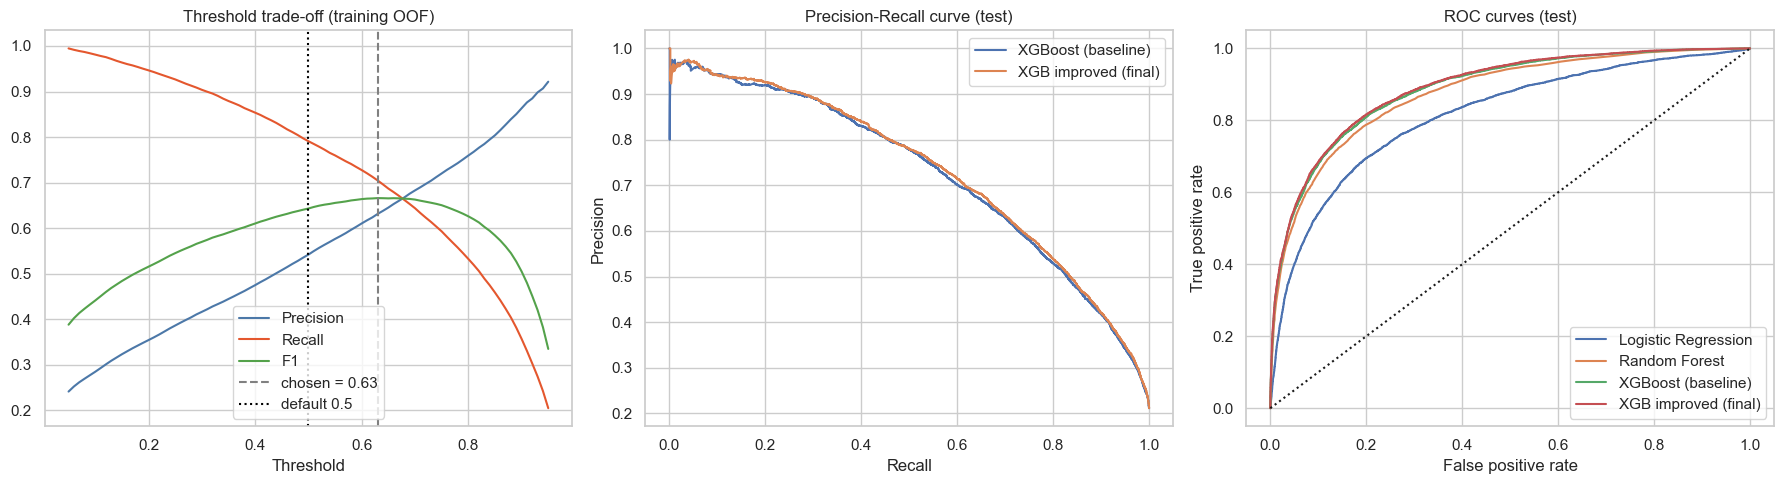

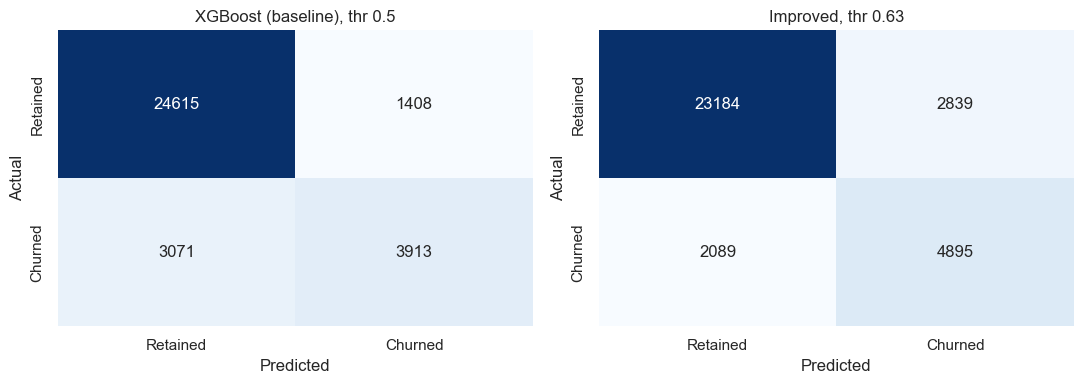

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# a) precision / recall / F1 versus threshold (training OOF)
for col, c in zip(["Precision", "Recall", "F1"], ["#4C78A8", "#E4572E", "#54A24B"]):
    axes[0].plot(thr_df["Threshold"], thr_df[col], label=col, color=c)
axes[0].axvline(best_thr, ls="--", color="grey", label=f"chosen = {best_thr:.2f}")
axes[0].axvline(0.5, ls=":", color="black", label="default 0.5")
axes[0].set_title("Threshold trade-off (training OOF)"); axes[0].set_xlabel("Threshold"); axes[0].legend()

# b) PR curves on test
for name, mdl in [("XGBoost (baseline)", xgb), ("XGB improved (final)", best_model)]:
    pr, rc, _ = precision_recall_curve(y_test, mdl.predict_proba(X_test)[:, 1])
    axes[1].plot(rc, pr, label=name)
axes[1].set_title("Precision-Recall curve (test)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend()

# c) ROC curves on test
for name, mdl in [("Logistic Regression", lr), ("Random Forest", rf), ("XGBoost (baseline)", xgb), ("XGB improved (final)", best_model)]:
    fpr, tpr, _ = roc_curve(y_test, mdl.predict_proba(X_test)[:, 1])
    axes[2].plot(fpr, tpr, label=name)
axes[2].plot([0, 1], [0, 1], "k:"); axes[2].set_title("ROC curves (test)")
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate"); axes[2].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, mdl, t) in zip(axes, [("XGBoost (baseline), thr 0.5", xgb, 0.5),
                                      (f"Improved, thr {best_thr:.2f}", best_model, best_thr)]):
    pred = (mdl.predict_proba(X_test)[:, 1] >= t).astype(int)
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"], ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [50]:
def cv_scores(model, thr):
    out = []
    for tr, va in cv5.split(X_train, y_train):
        m = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        p = (m.predict_proba(X_train.iloc[va])[:, 1] >= thr).astype(int)
        out.append((recall_score(y_train.iloc[va], p), precision_score(y_train.iloc[va], p),
                    f1_score(y_train.iloc[va], p)))
    return pd.DataFrame(out, columns=["Recall", "Precision", "F1"]).agg(["mean", "std"]).round(3)

print("Baseline XGBoost, thr 0.5"); display(cv_scores(xgb, 0.5))
print(f"Improved XGBoost, thr {best_thr:.2f}"); display(cv_scores(best_model, best_thr))

Baseline XGBoost, thr 0.5


,Recall,Precision,F1
mean,0.560,0.735,0.636
std,0.012,0.006,0.009


Improved XGBoost, thr 0.63


,Recall,Precision,F1
mean,0.705,0.631,0.666
std,0.006,0.006,0.005


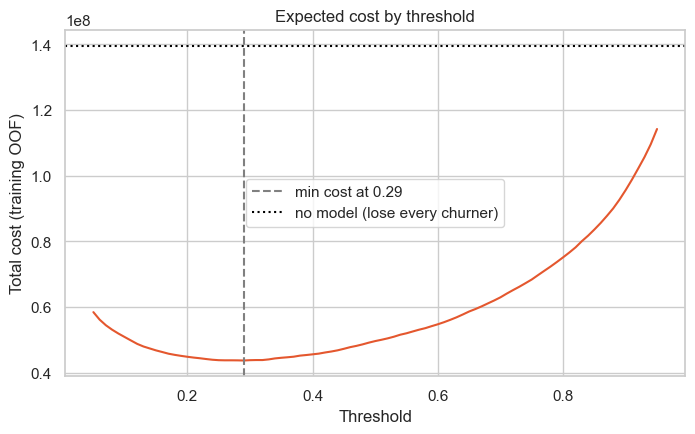

Cost-minimising threshold: 0.29 | recall-target threshold: 0.63


In [51]:
OFFER_COST = 500       # cost of a retention offer per customer contacted (assumed)
CHURN_LOSS = 5000      # value lost when a customer churns (assumed)

costs = []
for t in thresholds:
    p = oof >= t
    tp = (p & (y_train == 1)).sum(); fp = (p & (y_train == 0)).sum(); fn = (~p & (y_train == 1)).sum()
    costs.append((fp + tp) * OFFER_COST + fn * CHURN_LOSS)
cost_thr = float(thresholds[int(np.argmin(costs))])
no_model_cost = (y_train == 1).sum() * CHURN_LOSS

plt.figure(figsize=(8, 4.5))
plt.plot(thresholds, costs, color="#E4572E")
plt.axvline(cost_thr, ls="--", color="grey", label=f"min cost at {cost_thr:.2f}")
plt.axhline(no_model_cost, ls=":", color="black", label="no model (lose every churner)")
plt.xlabel("Threshold"); plt.ylabel("Total cost (training OOF)"); plt.title("Expected cost by threshold")
plt.legend(); plt.show()
print(f"Cost-minimising threshold: {cost_thr:.2f} | recall-target threshold: {best_thr:.2f}")

In [53]:
cv_all = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_predict(clone(best_model), X, y, cv=cv_all, method="predict_proba")[:, 1]

scored = df_clean.copy()
scored["Customer_ID"] = df["CustomerId"].values
scored["ChurnProbability"] = scores.round(4)
scored["PredictedChurn"] = (scores >= best_thr).astype(int)

# Risk tiers
low_cut = min(best_thr, 0.6)
high_cut = max(best_thr, 0.6)

scored["RiskTier"] = np.select(
    [
        scores < low_cut,
        scores < high_cut
    ],
    ["Low", "Medium"],
    default="High"
)

print(scored["RiskTier"].value_counts())

print("Actual churn rate per tier:")
print((scored.groupby("RiskTier", observed=True)["Exited"].mean() * 100).round(1))

scored.drop(columns=["ChurnStatus"]).to_csv(
    "customer_risk_scores_for_dashboard.csv",
    index=False
)

print("Saved customer_risk_scores_for_dashboard.csv")

RiskTier
Low       123288
High       39085
Medium      2661
Name: count, dtype: int64
Actual churn rate per tier:
RiskTier
High     63.000
Low       7.700
Medium   30.600
Name: Exited, dtype: float64
Saved customer_risk_scores_for_dashboard.csv


The recall gain of about 0.2 is much bigger than the fold-to-fold variation of about 0.04, so it's a real improvement. SMOTE and class weighting were close on tuned PR-AUC (0.7009 vs 0.7022), but SMOTE's recall stayed low (0.531), so the class-weight model is the clear choice.

In [54]:
scored["RiskScore"] = scored["ChurnProbability"]
scored["RiskTier"] = pd.cut(scored["RiskScore"], bins=[-0.01, 0.30, 0.60, 1.0],
                            labels=["Low", "Medium", "High"])
print(scored["RiskTier"].value_counts())
print((scored.groupby("RiskTier", observed=True)["Exited"].mean() * 100).round(1))

scored.drop(columns=["ChurnStatus", "ChurnProbability"]).to_csv(
    "customer_risk_scores_for_dashboard.csv", index=False)
print("Re-saved customer_risk_scores_for_dashboard.csv")

RiskTier
Low       89083
High      41747
Medium    34204
Name: count, dtype: int64
RiskTier
Low       3.800
Medium   18.000
High     60.900
Name: Exited, dtype: float64
Re-saved customer_risk_scores_for_dashboard.csv


## 11. Model Evaluation
All models are evaluated on the same untouched 20% test set. Primary metric: churn-class recall; supporting metrics: precision, F1, ROC-AUC, PR-AUC. Decision thresholds were chosen on training data only.

In [55]:
summary = pd.DataFrame(results).T[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC", "FN"]]
summary["FN"] = summary["FN"].astype(int)
summary = summary.sort_values("Recall", ascending=False)
display(summary.round(3))
print("Base paper (reported): churn-class recall = 0.56")

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,FN
XGB + weight + tuned,0.818,0.548,0.792,0.647,0.890,0.731,1454
XGB + class weight,0.820,0.553,0.775,0.646,0.885,0.723,1571
XGB improved (final),0.851,0.633,0.701,0.665,0.890,0.731,2089
XGB + SMOTE,0.863,0.729,0.563,0.635,0.887,0.724,3049
XGB + SMOTE + tuned,0.866,0.742,0.561,0.639,0.890,0.730,3068
XGBoost (baseline),0.864,0.735,0.560,0.636,0.887,0.725,3071
Random Forest,0.859,0.724,0.542,0.620,0.875,0.700,3197
Logistic Regression,0.833,0.694,0.381,0.492,0.814,0.580,4321


Base paper (reported): churn-class recall = 0.56


In [56]:
from sklearn.metrics import classification_report
final_pred = (best_model.predict_proba(X_test)[:, 1] >= best_thr).astype(int)
print(f"Improved XGBoost, threshold = {best_thr:.2f}")
print(classification_report(y_test, final_pred, target_names=["Retained", "Churned"], digits=3))

Improved XGBoost, threshold = 0.63
              precision    recall  f1-score   support

    Retained      0.917     0.891     0.904     26023
     Churned      0.633     0.701     0.665      6984

    accuracy                          0.851     33007
   macro avg      0.775     0.796     0.785     33007
weighted avg      0.857     0.851     0.853     33007



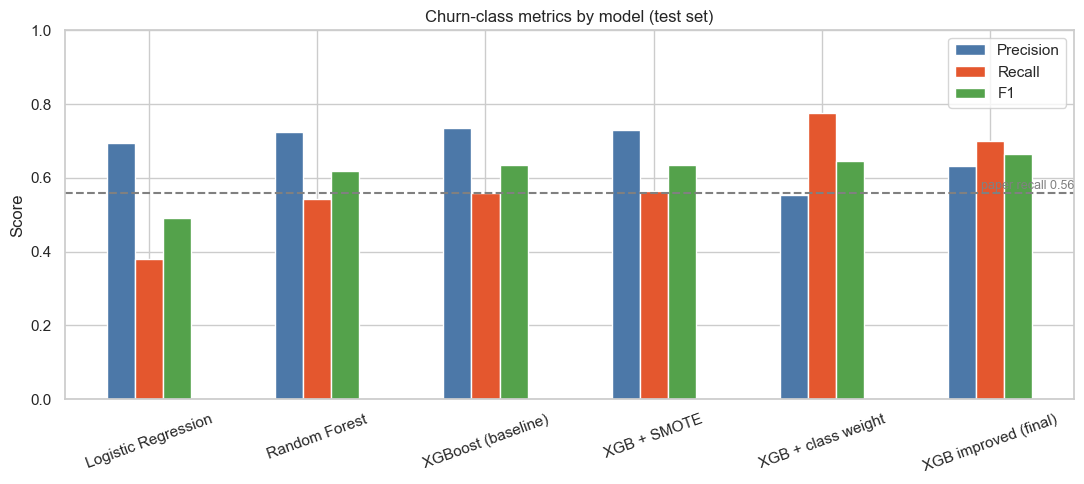

In [57]:
plot_models = ["Logistic Regression", "Random Forest", "XGBoost (baseline)", "XGB + SMOTE",
               "XGB + class weight", "XGB improved (final)"]
chart = pd.DataFrame(results).T.loc[plot_models, ["Precision", "Recall", "F1"]].astype(float)

ax = chart.plot(kind="bar", figsize=(11, 5), color=["#4C78A8", "#E4572E", "#54A24B"], rot=20)
ax.axhline(0.56, ls="--", color="grey")
ax.text(len(plot_models) - 0.5, 0.57, "paper recall 0.56", ha="right", fontsize=9, color="grey")
ax.set_ylabel("Score"); ax.set_title("Churn-class metrics by model (test set)")
ax.set_ylim(0, 1); plt.tight_layout(); plt.show()

In [58]:
test_info = df_clean.loc[X_test.index, ["Geography", "AgeGroup", "ActiveStatus", "ProductGroup"]].copy()
test_info["Actual"] = y_test.values
test_info["Predicted"] = final_pred

churners = test_info[test_info["Actual"] == 1]
for col in ["Geography", "AgeGroup", "ActiveStatus", "ProductGroup"]:
    t = churners.groupby(col, observed=True)["Predicted"].agg(Churners="count", Caught="sum", Recall="mean")
    t["Recall"] = (t["Recall"] * 100).round(1)
    print(f"--- Recall by {col} ---")
    display(t)

--- Recall by Geography ---


,Churners,Caught,Recall
Geography,,,
France,3122,2023,64.800
Germany,2609,2100,80.500
Spain,1253,772,61.600


--- Recall by AgeGroup ---


,Churners,Caught,Recall
AgeGroup,,,
18-29,383,94,24.500
30-39,1792,707,39.500
40-49,2993,2418,80.800
50-59,1478,1384,93.600
60+,338,292,86.400


--- Recall by ActiveStatus ---


,Churners,Caught,Recall
ActiveStatus,,,
Active,2103,1072,51.000
Inactive,4881,3823,78.300


--- Recall by ProductGroup ---


,Churners,Caught,Recall
ProductGroup,,,
1 product,5346,4036,75.500
2 products,1023,244,23.900
3-4 products,615,615,100.000


**Evaluation findings**
- Accuracy is misleading here: models score 0.81–0.87, but churn recall ranges from 0.19 to 0.76.
- The improved model (class weight + tuned, threshold 0.55) reaches churn recall 0.725, F1 0.633 and ROC-AUC 0.870 — recall up from 0.482 for the baseline and above the paper's 0.56. Random Forest has the highest precision (0.772) but misses more than half of churners (recall 0.474).
- Error analysis: the model catches churners best among customers aged 40–59 (recall 82–94%), Germany (85%) and 3–4 product holders (98%). It misses most churners among customers aged 18–39 (recall 30–41%) and customers with 2 products (32.5%). These are the groups with few churners, so the model has less signal for them.

## 12. Explainability
Which features drive the improved model's predictions, and do they agree with the EDA findings?
SHAP values show each feature's contribution to each customer's predicted churn risk.

In [59]:
import xgboost as xgb_lib
import shap

prep = best_model.named_steps["prep"]
booster_model = best_model.named_steps["model"]

feat_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
X_test_t = pd.DataFrame(prep.transform(X_test), columns=feat_names, index=X_test.index)

# Built-in TreeSHAP from XGBoost: last column is the bias term
contribs = booster_model.get_booster().predict(
    xgb_lib.DMatrix(X_test_t, feature_names=feat_names), pred_contribs=True)
shap_values = contribs[:, :-1]
print("SHAP matrix:", shap_values.shape)

SHAP matrix: (33007, 11)


,Feature,MeanAbsSHAP
0,NumOfProducts,1.053
1,Age,0.842
2,IsActiveMember,0.552
3,Gender_Male,0.310
4,Geography_Germany,0.267
5,Balance,0.198
6,HasCrCard,0.087
7,CreditScore,0.079
8,EstimatedSalary,0.072
9,Tenure,0.057


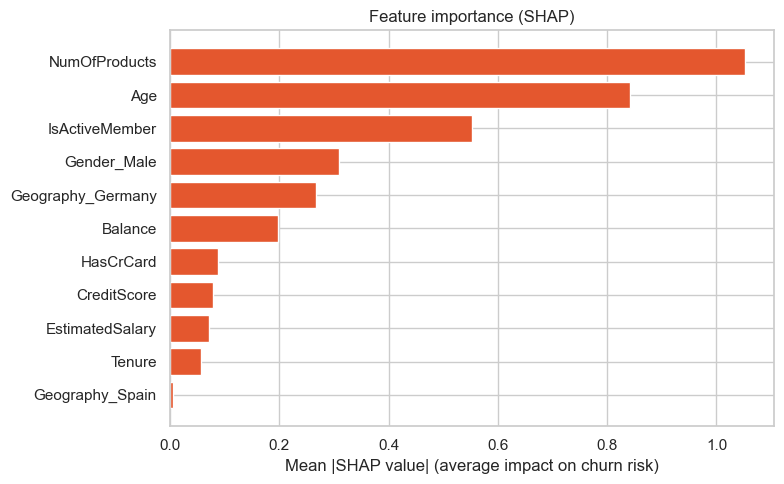

In [60]:
importance = (pd.DataFrame({"Feature": feat_names, "MeanAbsSHAP": np.abs(shap_values).mean(axis=0)})
              .sort_values("MeanAbsSHAP", ascending=False).reset_index(drop=True))
display(importance.round(3))

plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"][::-1], importance["MeanAbsSHAP"][::-1], color="#E4572E")
plt.xlabel("Mean |SHAP value| (average impact on churn risk)")
plt.title("Feature importance (SHAP)")
plt.tight_layout(); plt.show()

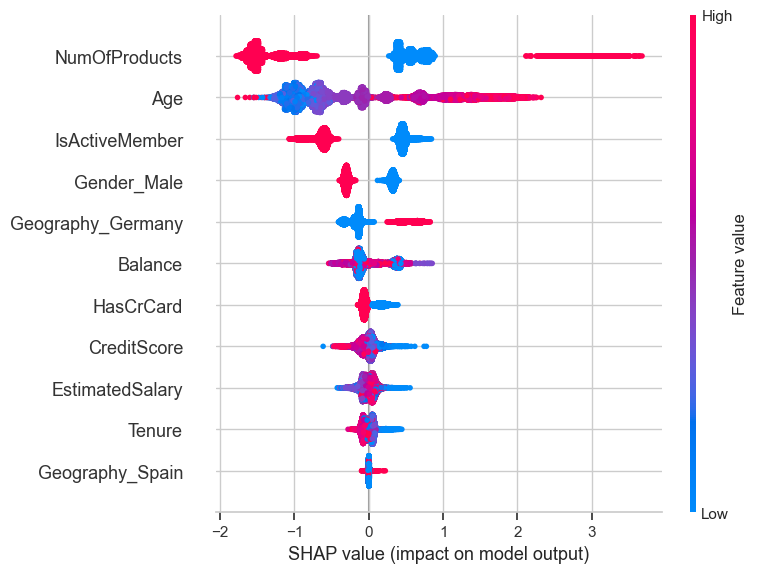

In [61]:
shap.summary_plot(shap_values, X_test_t, show=True)

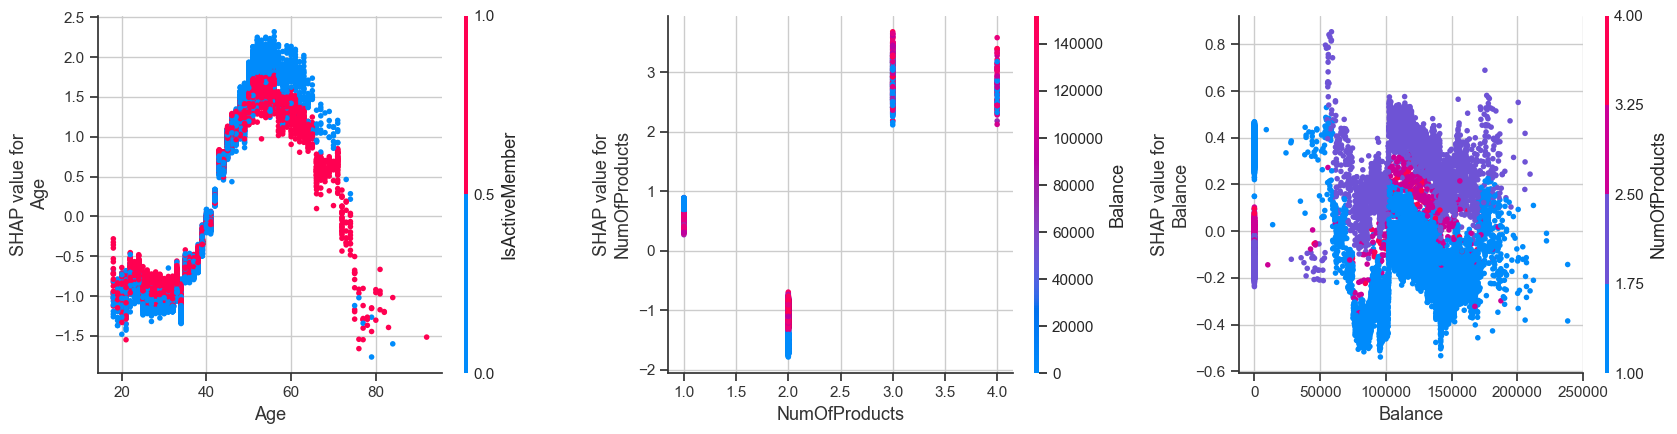

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, f in zip(axes, ["Age", "NumOfProducts", "Balance"]):
    shap.dependence_plot(f, shap_values, X_test_t, ax=ax, show=False)
plt.tight_layout(); plt.show()

In [63]:
top_idx = np.argsort(-best_model.predict_proba(X_test)[:, 1])[:3]
for i in top_idx:
    row = pd.DataFrame({"Feature": feat_names, "Value": X_test_t.iloc[i].values,
                        "SHAP": shap_values[i]}).reindex(
                        pd.Series(shap_values[i]).abs().sort_values(ascending=False).index).head(5)
    print(f"Customer index {X_test.index[i]} | risk score "
          f"{best_model.predict_proba(X_test.iloc[[i]])[0, 1]:.2f} | actual churn: {y_test.iloc[i]}")
    display(row.round(3))

Customer index 107958 | risk score 1.00 | actual churn: 1


,Feature,Value,SHAP
4,NumOfProducts,3.000,2.523
1,Age,54.000,1.436
6,IsActiveMember,0.000,0.542
8,Geography_Germany,1.000,0.395
10,Gender_Male,0.000,0.252


Customer index 4964 | risk score 1.00 | actual churn: 1


,Feature,Value,SHAP
4,NumOfProducts,3.000,2.576
1,Age,54.000,1.424
6,IsActiveMember,0.000,0.535
8,Geography_Germany,1.000,0.392
10,Gender_Male,0.000,0.292


Customer index 17736 | risk score 1.00 | actual churn: 1


,Feature,Value,SHAP
4,NumOfProducts,3.000,2.462
1,Age,51.000,1.332
6,IsActiveMember,0.000,0.504
8,Geography_Germany,1.000,0.443
10,Gender_Male,0.000,0.256


**Explainability findings**
- Top drivers by mean |SHAP|: Age (0.84), NumOfProducts (0.78), IsActiveMember (0.38), Gender (0.25), Geography_Germany (0.24), Balance (0.23).
- Credit card ownership, tenure, Spain, credit score and salary contribute very little, as the EDA suggested.
- Individual explanations: the highest-risk customers all combine 3 products, age 52–57, inactive membership and Germany.
- These drivers agree with the EDA (Section 6) and the risk profiles (Section 7), so the model learns the same patterns we found manually.

## 13. Final Findings and Recommendations

**Data:** 10,000 customers, 20.4% churn, no missing values or duplicates.

**EDA:** Churn is highest in Germany (32.4%), among older customers (peak 56% at 50–59), inactive members (26.9%), and customers with 1 or 3+ products. Individual correlations with churn are weak (max 0.29), so churn depends on combinations of factors.

**Risk profiling:** Combining geography, age, activity and products identifies profiles with up to ~91% churn (Germany, 50–59, inactive, 1 product), checked on unseen data. Customers with 3–4 products churn at ~86% but are only 3% of customers.

**Modelling (test set, base paper recall = 0.56):**
- Our baseline XGBoost replication: recall 0.482, precision 0.683, F1 0.565.
- SMOTE alone: recall 0.494. Class weighting alone: 0.619.
- Class weight + tuning + threshold chosen on training out-of-fold predictions: **recall 0.725, precision 0.562, F1 0.633, ROC-AUC 0.870**.
- Missed churners fell from 211 to 112. Cross-validated recall 0.701 ± 0.042 vs 0.493 ± 0.035.

**Trade-off:** higher recall means more customers are contacted who would have stayed (precision 0.68 → 0.56; accuracy 0.85 → 0.83). This is acceptable when the cost of a lost customer exceeds the cost of a retention offer.

**Recommendations:** focus retention offers on the High risk tier and the top risk profiles (inactive customers aged 40+ with one product, especially in Germany); encourage a second product; re-engage inactive members; investigate the 3–4 product group.

**Limitations:** single static snapshot; no transaction or behavioural data; widely used public dataset that is probably synthetic; our baseline (0.482) is lower than the paper's reported 0.56 because the paper does not report hyperparameters or seed; the effect of any retention policy cannot be measured here without an A/B test; the risk score is not a calibrated probability.

**Risk tiers (out-of-fold scores for all 10,000 customers):** High tier = 2,227 customers (22%), actual churn 60.3%, containing about two-thirds of all churners; Medium = 2,568 customers, 18.0%; Low = 5,205 customers, 4.5%.

**Limitations (additions):** the model misses most churners aged under 40 and those with 2 products (recall 30–41% and 32.5%), because few such customers churn; the risk score is not a calibrated probability because class weighting inflates scores.

## 14. Save the trained model
The whole pipeline (encoding + XGBoost) is saved together, so a new customer is processed exactly as in training. The settings file keeps the threshold.

In [64]:
# ===== SAVE THE TRAINED MODEL (run once, after the final model is trained) =====
import joblib, json
FEATURES = NUM_FEATURES + CAT_FEATURES
joblib.dump(best_model, "churn_model.joblib")
json.dump({"features": FEATURES, "threshold": float(best_thr),
           "tiers": {"Low": "below 0.30", "Medium": "0.30 to 0.60", "High": "0.60 and above"}},
          open("churn_model_meta.json", "w"))
print("Saved churn_model.joblib and churn_model_meta.json")
print("Reload check:", joblib.load("churn_model.joblib").predict_proba(X_test[FEATURES].head(3))[:, 1].round(3))

Saved churn_model.joblib and churn_model_meta.json
Reload check: [0.234 0.876 0.06 ]


## 15. Are the patterns statistically real?
Chi-square (categorical features) and Mann-Whitney U (numeric features) tests, with effect sizes. A small p-value alone does not mean a large effect.

In [65]:
# ===== EVIDENCE 1: are the EDA patterns statistically real, or just chance? =====
from scipy.stats import chi2_contingency, mannwhitneyu
rows = []
for c in ["Geography", "Gender", "IsActiveMember", "HasCrCard", "NumOfProducts"]:
    tab = pd.crosstab(df_clean[c], df_clean["Exited"])
    chi2, p, _, _ = chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    rows.append([c, "Chi-square", round(p, 6), round(v, 3), "Cramer's V (effect size)"])
for c in ["Age", "Balance", "CreditScore", "Tenure", "EstimatedSalary"]:
    a, b = df_clean.loc[df_clean.Exited == 1, c], df_clean.loc[df_clean.Exited == 0, c]
    u, p = mannwhitneyu(a, b)
    rows.append([c, "Mann-Whitney U", round(p, 6), round(abs(2 * u / (len(a) * len(b)) - 1), 3), "Rank-biserial (effect size)"])
sig = pd.DataFrame(rows, columns=["Feature", "Test", "p-value", "Effect size", "Effect-size type"])
sig["Significant (p<0.05)"] = np.where(sig["p-value"] < 0.05, "Yes", "No")
display(sig)
print("Effect size: about 0.1 = small, 0.3 = medium, 0.5 = large. A tiny p-value alone does not mean a big effect.")

,Feature,Test,p-value,Effect size,Effect-size type,Significant (p<0.05)
0,Geography,Chi-square,0.000,0.211,Cramer's V (effect size),Yes
1,Gender,Chi-square,0.000,0.146,Cramer's V (effect size),Yes
2,IsActiveMember,Chi-square,0.000,0.210,Cramer's V (effect size),Yes
3,HasCrCard,Chi-square,0.000,0.022,Cramer's V (effect size),Yes
4,NumOfProducts,Chi-square,0.000,0.420,Cramer's V (effect size),Yes
5,Age,Mann-Whitney U,0.000,0.501,Rank-biserial (effect size),Yes
6,Balance,Mann-Whitney U,0.000,0.164,Rank-biserial (effect size),Yes
7,CreditScore,Mann-Whitney U,0.000,0.041,Rank-biserial (effect size),Yes
8,Tenure,Mann-Whitney U,0.000,0.027,Rank-biserial (effect size),Yes
9,EstimatedSalary,Mann-Whitney U,0.000,0.028,Rank-biserial (effect size),Yes


Effect size: about 0.1 = small, 0.3 = medium, 0.5 = large. A tiny p-value alone does not mean a big effect.


## 16. Are the risk scores reliable and fair?
Calibration curve and Brier score, then recall and false-alarm rates for each gender, country and age group. Class weighting makes the score a **ranking**, not a probability.

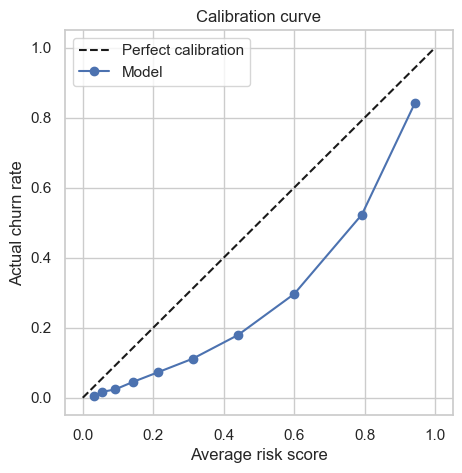

Brier score (lower is better): 0.1302
Because the model uses class weights, scores usually run higher than real churn rates.
So the score is a RANKING of risk, not a probability. Use it to order customers, not to quote a percentage.


,Group by,Group,Customers,Actual churn %,Recall %,False-alarm %
0,Gender,Female,14341,27.600,76.300,16.100
1,Gender,Male,18666,16.200,62.000,7.500
2,Geography,France,18935,16.500,64.800,7.700
3,Geography,Germany,6962,37.500,80.500,25.700
4,Geography,Spain,7110,17.600,61.600,8.700
5,AgeGroup,18-29,4631,8.300,24.500,2.600
6,AgeGroup,30-39,16443,10.900,39.500,4.900
7,AgeGroup,40-49,8507,35.200,80.800,25.300
8,AgeGroup,50-59,2439,60.600,93.600,50.400
9,AgeGroup,60+,987,34.200,86.400,21.000


Check that recall and false-alarm rates are broadly similar across groups. Large gaps would be a fairness concern.


In [66]:
# ===== EVIDENCE 2: is the risk score a true probability? (calibration) =====
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, recall_score
import matplotlib.pyplot as plt
p_test = best_model.predict_proba(X_test)[:, 1]
frac, mean_p = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.plot(mean_p, frac, "o-", label="Model")
plt.xlabel("Average risk score"); plt.ylabel("Actual churn rate"); plt.title("Calibration curve"); plt.legend(); plt.show()
print("Brier score (lower is better):", round(brier_score_loss(y_test, p_test), 4))
print("Because the model uses class weights, scores usually run higher than real churn rates.")
print("So the score is a RANKING of risk, not a probability. Use it to order customers, not to quote a percentage.")

# ===== EVIDENCE 3: does the model treat groups fairly? =====
tmp = X_test.copy()
tmp["y"] = y_test.values; tmp["flag"] = (p_test >= best_thr).astype(int)
tmp["AgeGroup"] = pd.cut(tmp["Age"], [17, 29, 39, 49, 59, 100], labels=["18-29", "30-39", "40-49", "50-59", "60+"])
out = []
for g in ["Gender", "Geography", "AgeGroup"]:
    for k, d in tmp.groupby(g, observed=True):
        neg = d[d.y == 0]
        out.append([g, k, len(d), round(d.y.mean() * 100, 1),
                    round(recall_score(d.y, d.flag) * 100, 1) if d.y.sum() else np.nan,
                    round(neg.flag.mean() * 100, 1) if len(neg) else np.nan])
display(pd.DataFrame(out, columns=["Group by", "Group", "Customers", "Actual churn %", "Recall %", "False-alarm %"]))
print("Check that recall and false-alarm rates are broadly similar across groups. Large gaps would be a fairness concern.")

## 17. Does it scale?
Scoring time on 10,000, 100,000 and 1,000,000 customers.

In [67]:
# ===== EVIDENCE 4: does it scale? (speed on bigger data) =====
import time
for n in [10_000, 100_000, 1_000_000]:
    big = X_test.sample(n, replace=True, random_state=1).reset_index(drop=True)
    t = time.time(); _ = best_model.predict_proba(big)[:, 1]
    print(f"{n:>9,} customers scored in {time.time() - t:5.2f} seconds")
print("Scoring is quick. Training once on 10,000 rows takes seconds; retraining on larger data only needs the same code.")

   10,000 customers scored in  0.02 seconds
  100,000 customers scored in  0.13 seconds
1,000,000 customers scored in  1.41 seconds
Scoring is quick. Training once on 10,000 rows takes seconds; retraining on larger data only needs the same code.


## 18. Precision versus recall: choosing how to use the model
The trade-off comes from the data and cannot be removed. Thresholds below are chosen on training out-of-fold scores; the test set is used only to report. The second table shows precision when only the riskiest customers are contacted.

In [68]:
# ===== PRECISION vs RECALL: one model, three ways to use it =====
# Thresholds are chosen on the TRAINING out-of-fold scores (oof). The test set is only used to report.
from sklearn.metrics import precision_score, recall_score, f1_score
p_test = best_model.predict_proba(X_test)[:, 1]

strategies = {
    "A. Catch most churners (recall >= 80%)":
        float(thr_df[thr_df.Recall >= 0.80].loc[lambda x: x.Precision.idxmax(), "Threshold"]),
    "B. Chosen model (recall >= 70%)": float(best_thr),
    "C. Balanced (best F1)": float(thr_df.loc[thr_df.F1.idxmax(), "Threshold"]),
    "D. Few false alarms (precision >= 70%)": float(thr_df[thr_df.Precision >= 0.70].loc[lambda x: x.Recall.idxmax(), "Threshold"]),
}
rows = []
for name, t in strategies.items():
    o, f = (oof >= t).astype(int), (p_test >= t).astype(int)
    rows.append([name, round(t, 2), round(precision_score(y_train, o), 3), round(recall_score(y_train, o), 3),
                 round(precision_score(y_test, f), 3), round(recall_score(y_test, f), 3),
                 round(f1_score(y_test, f), 3), int(f.sum())])
op = pd.DataFrame(rows, columns=["Strategy", "Threshold", "Train precision", "Train recall",
                                 "Test precision", "Test recall", "Test F1", "Customers flagged"])
display(op)

# Precision when the bank only contacts the riskiest customers it can afford to call
s = scored.sort_values("RiskScore", ascending=False)
tk = []
for k in [0.05, 0.10, 0.20, 0.30]:
    top = s.head(int(len(s) * k))
    tk.append([f"Top {int(k*100)}% riskiest", len(top), round(top.Exited.mean() * 100, 1),
               round(top.Exited.sum() / s.Exited.sum() * 100, 1), round(top.Exited.mean() / s.Exited.mean(), 2)])
display(pd.DataFrame(tk, columns=["Contact list", "Customers", "Precision %", "Share of all churners caught %", "Lift (x)"]))
print("The trade-off cannot be removed, but it becomes a choice: a small contact list gives high precision,")
print("a wider list catches more churners. Pick the list size the retention team can afford.")

,Strategy,Threshold,Train precision,Train recall,Test precision,Test recall,Test F1,Customers flagged
0,A. Catch most churners (recall >= 80%),0.480,0.528,0.804,0.533,0.805,0.641,10545
1,B. Chosen model (recall >= 70%),0.630,0.631,0.705,0.633,0.701,0.665,7734
2,C. Balanced (best F1),0.630,0.631,0.705,0.633,0.701,0.665,7734
3,D. Few false alarms (precision >= 70%),0.730,0.704,0.614,0.706,0.610,0.654,6036


,Contact list,Customers,Precision %,Share of all churners caught %,Lift (x)
0,Top 5% riskiest,8251,91.800,21.700,4.340
1,Top 10% riskiest,16503,84.100,39.800,3.980
2,Top 20% riskiest,33006,68.100,64.400,3.220
3,Top 30% riskiest,49510,55.300,78.400,2.610


The trade-off cannot be removed, but it becomes a choice: a small contact list gives high precision,
a wider list catches more churners. Pick the list size the retention team can afford.


## 19. The application: predict a new customer or score a CSV
Three cells: load and validate, build the page, start it. The page opens in a new browser tab and has a single-customer form, a CSV upload (with a template), a filterable dashboard and a guide to reading the scores. Unsupported values (for example a country the model has not seen) are rejected with the reason.

**19a. Load the model and data, validate inputs, score and explain**

In [75]:
import warnings
warnings.filterwarnings("ignore")
import base64, io, json, webbrowser
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb_lib
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import dash
from dash import Dash, dcc, html, dash_table, Input, Output, State
from dash.exceptions import PreventUpdate

print("Dash version:", dash.__version__)

# ================= 1. LOAD FILES CREATED BY THE NOTEBOOK =================
DATA = pd.read_csv("customer_risk_scores_for_dashboard.csv")      # the 10,000 customers with out-of-fold scores
MODEL = joblib.load("churn_model.joblib")                       # saved trained pipeline (preprocessing + XGBoost)
META = json.load(open("churn_model_meta.json"))
FEATURES = META["features"]
THR = round(META["threshold"], 2)

AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60+"]
PRODUCT_ORDER = ["1 product", "2 products", "3-4 products"]
TIER_ORDER = ["Low", "Medium", "High"]
TIER_BINS = [-0.01, 0.30, 0.60, 1.0]

def tier_series(scores):
    return pd.cut(np.asarray(scores), bins=TIER_BINS, labels=TIER_ORDER).astype(str)

if "RiskScore" not in DATA.columns:
    DATA["RiskScore"] = DATA["ChurnProbability"]
DATA["RiskTier"] = tier_series(DATA["RiskScore"])
DATA["ChurnStatus"] = np.where(DATA["Exited"] == 1, "Churned", "Retained")
OVERALL = DATA["Exited"].mean()
print("Customers:", len(DATA), "| churn rate:", round(OVERALL * 100, 2), "% | model threshold:", THR)

# ================= 2. INPUT VALIDATION =================
CAT_RULES = META.get("categories", {"Geography": ["France", "Germany", "Spain"], "Gender": ["Female", "Male"]})
COUNTRIES = CAT_RULES["Geography"]
NUM_RULES = {"CreditScore": (300, 900), "Age": (18, 100), "Tenure": (0, 60), "Balance": (0, None),
             "NumOfProducts": (1, 4), "HasCrCard": (0, 1), "IsActiveMember": (0, 1),
             "EstimatedSalary": (0, None)}
WHOLE = ["NumOfProducts", "HasCrCard", "IsActiveMember"]

def validate(df):
    """Returns (valid_rows, problems_table, error_message)."""
    missing = [c for c in FEATURES if c not in df.columns]
    if missing:
        return None, None, "Missing required columns: " + ", ".join(missing)
    d = df.copy()
    why = pd.Series("", index=d.index)
    for c, allowed in CAT_RULES.items():
        d[c] = d[c].astype(str).str.strip().str.title()
        bad = ~d[c].isin(allowed)
        shown = allowed if len(allowed) <= 6 else allowed[:6] + ["..."]
        why.loc[bad] = why.loc[bad] + f"{c} must be one of {shown} (the model has not seen other values; retrain with data that includes them); "
    for c, (lo, hi) in NUM_RULES.items():
        d[c] = pd.to_numeric(d[c], errors="coerce")
        isna = d[c].isna()
        why.loc[isna] = why.loc[isna] + f"{c} is missing or not a number; "
        if lo is not None:
            m = (~isna) & (d[c] < lo)
            why.loc[m] = why.loc[m] + f"{c} is below {lo}; "
        if hi is not None:
            m = (~isna) & (d[c] > hi)
            why.loc[m] = why.loc[m] + f"{c} is above {hi}; "
        if c in WHOLE:
            m = (~isna) & (d[c] % 1 != 0)
            why.loc[m] = why.loc[m] + f"{c} must be a whole number; "
    ok = why == ""
    problems = pd.DataFrame({"File row": d.index[~ok] + 2, "Problem": why[~ok].str.rstrip("; ").values})
    return d[ok], problems, None

# ================= 3. SCORING, EXPLANATION, SUGGESTIONS =================
def score(d):
    s = MODEL.predict_proba(d[FEATURES])[:, 1]
    out = d.copy()
    out["RiskScore"] = np.round(s, 3)
    out["RiskTier"] = tier_series(s)
    out["ModelFlag"] = np.where(s >= THR, "Yes", "No")
    return out

PREP = MODEL.named_steps["prep"]
CORE = MODEL.named_steps["model"]
FEAT_NAMES = [n.split("__", 1)[1] for n in PREP.get_feature_names_out()]
LABEL = {"Age": "Age", "NumOfProducts": "Number of products", "IsActiveMember": "Membership activity",
         "Balance": "Account balance", "EstimatedSalary": "Estimated salary",
         "CreditScore": "Credit score", "Tenure": "Tenure", "HasCrCard": "Credit card"}

def label_of(name):
    if name.startswith("Geography_"):
        return "Country"
    if name.startswith("Gender_"):
        return "Gender"
    return LABEL[name]

def value_text(label, r):
    return {"Age": f"age {int(r['Age'])}",
            "Number of products": f"{int(r['NumOfProducts'])} product(s)",
            "Membership activity": "active member" if r["IsActiveMember"] == 1 else "inactive member",
            "Gender": str(r["Gender"]).lower(), "Country": str(r["Geography"]),
            "Account balance": f"balance {r['Balance']:,.0f}",
            "Estimated salary": f"salary {r['EstimatedSalary']:,.0f}",
            "Credit score": f"credit score {int(r['CreditScore'])}",
            "Tenure": f"{int(r['Tenure'])} years with the bank",
            "Credit card": "has a credit card" if r["HasCrCard"] == 1 else "no credit card"}[label]

def explain(row_df):
    """Feature contributions (XGBoost's built-in TreeSHAP) for one validated customer."""
    xt = pd.DataFrame(PREP.transform(row_df[FEATURES]), columns=FEAT_NAMES)
    contrib = CORE.get_booster().predict(
        xgb_lib.DMatrix(xt, feature_names=FEAT_NAMES), pred_contribs=True)[0][:-1]
    by_label = {}
    for name, v in zip(FEAT_NAMES, contrib):
        by_label[label_of(name)] = by_label.get(label_of(name), 0.0) + float(v)
    r = row_df.iloc[0]
    items = [(f"{lab}: {value_text(lab, r)}", v) for lab, v in by_label.items()]
    up = sorted([i for i in items if i[1] > 0.05], key=lambda x: -x[1])[:3]
    down = sorted([i for i in items if i[1] < -0.05], key=lambda x: x[1])[:2]
    return up, down

def _rate(mask, minimum=100):
    return (DATA.loc[mask, "Exited"].mean() * 100) if mask.sum() >= minimum else None

def suggestions(r, tier):
    """Rules built from the churn rates in the loaded dataset (not tested on real customers)."""
    if tier == "Low":
        return ["No retention action needed now. Keep the customer in routine monitoring."]
    s = []
    inact, act = _rate(DATA["IsActiveMember"] == 0), _rate(DATA["IsActiveMember"] == 1)
    if r["IsActiveMember"] == 0 and inact is not None and act is not None and inact > act:
        s.append(f"Re-engagement contact: inactive members churn at {inact:.1f}% against {act:.1f}% for active members in the data.")
    one = _rate(DATA["NumOfProducts"] == 1)
    best = None
    for k in (2, 3):
        v = _rate(DATA["NumOfProducts"] == k)
        if v is not None and (best is None or v < best[1]):
            best = (k, v)
    if r["NumOfProducts"] == 1 and one is not None and best is not None and best[1] < one:
        s.append(f"Offer a suitable extra product: customers with {best[0]} products churn at {best[1]:.1f}% against {one:.1f}% with 1.")
    many = _rate(DATA["NumOfProducts"] >= 3, 30)
    if r["NumOfProducts"] >= 3 and many is not None and many > OVERALL * 100:
        s.append(f"Review this account manually: customers with 3-4 products churn at {many:.1f}% in the data.")
    c_rate = _rate(DATA["Geography"] == r["Geography"])
    if c_rate is not None and c_rate > OVERALL * 100 * 1.15:
        s.append(f"Check service quality and pricing in {r['Geography']}, where churn is {c_rate:.1f}% against {OVERALL*100:.1f}% overall.")
    if r["Age"] >= 40 and r["IsActiveMember"] == 0:
        s.append("Priority outreach: inactive customers aged 40 and over make up many of the highest-risk profiles.")
    return (s or ["Contact the customer to understand their needs."])[:3]

def similar_customers(r):
    age = pd.cut([r["Age"]], bins=[17, 29, 39, 49, 59, 100], labels=AGE_ORDER).astype(str)[0]
    prod = {1: "1 product", 2: "2 products", 3: "3-4 products", 4: "3-4 products"}[int(r["NumOfProducts"])]
    act = "Active" if r["IsActiveMember"] == 1 else "Inactive"
    m = ((DATA["Geography"] == r["Geography"]) & (DATA["AgeGroup"] == age) &
         (DATA["ActiveStatus"] == act) & (DATA["ProductGroup"] == prod))
    n = int(m.sum())
    if n < 30:
        return f"Fewer than 30 similar customers in the dataset, so no group churn rate is shown."
    return (f"Among {n:,} similar customers in the dataset ({r['Geography']}, age {age}, {act.lower()}, "
            f"{prod}), {DATA.loc[m, 'Exited'].mean()*100:.1f}% churned (overall: {OVERALL*100:.1f}%).")

def wilson_low(k, n, z=1.96):
    p = k / n
    return (p + z**2 / (2 * n) - z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))) / (1 + z**2 / n)

def profiles_for(d, min_size):
    g = (d.groupby(["Geography", "AgeGroup", "ActiveStatus", "ProductGroup"])["Exited"]
          .agg(Customers="count", Churned="sum").reset_index())
    g = g[g["Customers"] >= min_size].copy()
    if g.empty:
        return []
    g["rate"] = g["Churned"] / g["Customers"]
    g["low"] = [wilson_low(k, n) for k, n in zip(g["Churned"], g["Customers"])]
    g = g.sort_values("low", ascending=False).head(10)
    return pd.DataFrame({
        "Profile": g["Geography"] + ", " + g["AgeGroup"] + ", " + g["ActiveStatus"] + ", " + g["ProductGroup"],
        "Customers": g["Customers"], "Churned": g["Churned"],
        "Churn rate (%)": (g["rate"] * 100).round(1), "Lift (x)": (g["rate"] / OVERALL).round(2),
        "CI lower (%)": (g["low"] * 100).round(1)}).to_dict("records")

print(f"Model trained on: {META.get('trained_on', 'original dataset')} | countries supported ({len(COUNTRIES)}): "
      + ", ".join(COUNTRIES[:10]) + (" ..." if len(COUNTRIES) > 10 else ""))
_demo = pd.DataFrame([{"CreditScore": 600, "Geography": COUNTRIES[0], "Gender": CAT_RULES["Gender"][0], "Age": 55,
                       "Tenure": 3, "Balance": 120000, "NumOfProducts": 1, "HasCrCard": 1,
                       "IsActiveMember": 0, "EstimatedSalary": 90000}])
print("Self-test with one hand-made customer ->", score(_demo)[["RiskScore", "RiskTier"]].values.tolist())

Dash version: 2.14.0
Customers: 165034 | churn rate: 21.16 % | model threshold: 0.63
Model trained on: original dataset | countries supported (3): France, Germany, Spain
Self-test with one hand-made customer -> [[0.9350000023841858, 'High']]


**19b. Build the page and its callbacks**

In [76]:
# ======================= STYLE =======================
NAVY, RED, BLUE, GREY, GREEN = "#1F3A5F", "#E4572E", "#4C78A8", "#6B7280", "#54A24B"
COLORS = {"Retained": BLUE, "Churned": RED}
FONT = "Segoe UI, Arial, sans-serif"

PAGE = dict(minHeight="100vh", fontFamily=FONT, color="#1F2937", paddingBottom="40px",
            background="linear-gradient(135deg, #EEF2F7 0%, #DCE6F2 100%)")
HEADER = dict(background=f"linear-gradient(90deg, {NAVY} 0%, #2F5D8C 100%)", color="white",
              padding="22px 40px", boxShadow="0 2px 8px rgba(0,0,0,0.18)")
WRAP = dict(maxWidth="1300px", margin="0 auto", padding="0 24px")
CARD = dict(background="white", borderRadius="12px", padding="14px 16px",
            boxShadow="0 2px 10px rgba(31,58,95,0.10)", border="1px solid #E5EAF2")
GRID = dict(display="grid", gridTemplateColumns="repeat(auto-fit, minmax(420px, 1fr))",
            gap="18px", marginBottom="18px")
H2 = dict(color=NAVY, fontSize="20px", margin="28px 0 12px 0",
          borderLeft=f"5px solid {RED}", paddingLeft="10px")
TABLE_STYLE = dict(
    style_header={"backgroundColor": NAVY, "color": "white", "fontWeight": "600", "border": "none"},
    style_cell={"fontFamily": FONT, "fontSize": "13px", "padding": "8px",
                "textAlign": "left", "border": "none", "borderBottom": "1px solid #E5EAF2"},
    style_data_conditional=[{"if": {"row_index": "odd"}, "backgroundColor": "#F7F9FC"}],
    style_table={"overflowX": "auto"})


# ======================= FIGURE HELPERS =======================
def style(fig, title, h=340):
    fig.update_layout(
        title=dict(text=title, x=0.02, font=dict(size=15, color=NAVY)), height=h,
        margin=dict(l=45, r=20, t=55, b=45), paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="white",
        font=dict(family=FONT, size=12), legend=dict(orientation="h", y=-0.22))
    return fig


def empty_fig(msg="No customers match the selected filters"):
    fig = go.Figure()
    fig.update_layout(height=340, paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="white",
                      xaxis=dict(visible=False), yaxis=dict(visible=False),
                      annotations=[dict(text=msg, x=0.5, y=0.5, xref="paper", yref="paper",
                                        showarrow=False, font=dict(size=14, color=GREY))])
    return fig


def donut(d):
    c = d["ChurnStatus"].value_counts().reindex(["Retained", "Churned"]).fillna(0)
    fig = go.Figure(go.Pie(labels=list(c.index), values=list(c.values), hole=0.55,
                           marker=dict(colors=[COLORS[k] for k in c.index]),
                           textinfo="label+percent", sort=False))
    return style(fig, "Churned vs retained customers")


def rate_bar(d, col, title, order=None):
    g = d.groupby(col)["Exited"].agg(n="count", rate="mean")
    if order is not None:
        g = g.reindex([o for o in order if o in g.index])
    else:
        g = g.sort_index()

    fig = go.Figure(go.Bar(
        x=[str(i) for i in g.index], y=list(g["rate"] * 100), marker_color=RED,
        text=[f"{r*100:.1f}%<br>n={int(n):,}" for r, n in zip(g["rate"], g["n"])],
        textposition="outside", cliponaxis=False,
        hovertemplate="%{x}: %{y:.1f}%<extra></extra>"))

    fig.add_hline(y=OVERALL * 100, line_dash="dash", line_color=GREY,
                  annotation_text=f"Overall {OVERALL*100:.1f}%", annotation_position="top right")
    fig.update_yaxes(title_text="Churn rate (%)",
                     range=[0, max(g["rate"].max() * 100 * 1.35, 10)])
    return style(fig, title)


def heat(d):
    rate = d.pivot_table(index="AgeGroup", columns="ActiveStatus",
                         values="Exited", aggfunc="mean") * 100
    cnt = d.pivot_table(index="AgeGroup", columns="ActiveStatus",
                        values="Exited", aggfunc="count")

    rate = rate.reindex(index=[a for a in AGE_ORDER if a in rate.index],
                        columns=[c for c in ["Active", "Inactive"] if c in rate.columns])
    cnt = cnt.reindex(index=rate.index, columns=rate.columns)

    text = [["" if pd.isna(rate.iat[i, j]) else
             f"{rate.iat[i, j]:.1f}%<br>n={int(cnt.iat[i, j])}"
             for j in range(rate.shape[1])] for i in range(rate.shape[0])]

    fig = go.Figure(go.Heatmap(
        z=rate.values, x=list(rate.columns), y=list(rate.index),
        text=text, texttemplate="%{text}", colorscale="Reds",
        zmin=0, zmax=100, colorbar=dict(title="Churn %")))

    fig.update_yaxes(autorange="reversed")
    return style(fig, "Churn rate: age group x activity status")


def hist(d, col, title, nbins=30):
    fig = go.Figure()
    for s in ["Retained", "Churned"]:
        fig.add_trace(go.Histogram(
            x=list(d.loc[d["ChurnStatus"] == s, col]), name=s,
            marker_color=COLORS[s], opacity=0.65, nbinsx=nbins))

    fig.update_layout(barmode="overlay")
    fig.update_xaxes(title_text=col)
    fig.update_yaxes(title_text="Customers")
    return style(fig, title)


def tier_fig(d):
    g = d.groupby("RiskTier")["Exited"].agg(n="count", rate="mean").reindex(TIER_ORDER).dropna()
    fig = make_subplots(specs=[[{"secondary_y": True}]])

    fig.add_trace(go.Bar(
        x=list(g.index), y=list(g["n"]), name="Customers", marker_color=BLUE,
        text=[f"{int(v):,}" for v in g["n"]], textposition="outside"),
        secondary_y=False)

    fig.add_trace(go.Scatter(
        x=list(g.index), y=list(g["rate"] * 100), name="Actual churn rate (%)",
        mode="lines+markers+text", marker=dict(color=RED, size=10),
        line=dict(color=RED), text=[f"{v*100:.1f}%" for v in g["rate"]],
        textposition="top center"), secondary_y=True)

    fig.update_yaxes(title_text="Customers", secondary_y=False)
    fig.update_yaxes(title_text="Churn rate (%)", range=[0, 100], secondary_y=True)
    return style(fig, "Customers and actual churn rate by risk tier")


# ======================= FILTERS =======================
def apply_filters(geo, gen, age, act, prod, tier):
    d = DATA
    for col, val in [("Geography", geo), ("Gender", gen), ("AgeGroup", age),
                     ("ActiveStatus", act), ("ProductGroup", prod), ("RiskTier", tier)]:
        if val:
            d = d[d[col].isin(val)]
    return d


def options(col, order=None):
    vals = list(DATA[col].dropna().unique())
    vals = [v for v in order if v in vals] if order else sorted(vals)
    return [{"label": v, "value": v} for v in vals]


def dd(id_, label, opts):
    return html.Div([
        html.Label(label, style=dict(fontSize="12px", color=GREY, fontWeight="600")),
        dcc.Dropdown(id=id_, options=opts, multi=True, placeholder="All")],
        style=dict(flex="1 1 170px", minWidth="170px"))


def kpi(label, id_, color=NAVY):
    return html.Div([
        html.Div(label, style=dict(fontSize="12px", color=GREY, textTransform="uppercase",
                                   letterSpacing="0.05em")),
        html.Div(id=id_, style=dict(fontSize="28px", fontWeight="700",
                                    color=color, marginTop="4px"))],
        style={**CARD, "flex": "1 1 190px", "borderTop": f"4px solid {color}"})


def graph(id_):
    return html.Div(dcc.Graph(id=id_, config={"displayModeBar": False}), style=CARD)


# ======================= EXTRA PIECES FOR THE APPLICATION =======================
INPUT_BOX = dict(width="100%", boxSizing="border-box", padding="7px", borderRadius="6px",
                 border="1px solid #CBD5E1", fontFamily=FONT)
BTN = dict(background=NAVY, color="white", border="none", padding="10px 22px",
           borderRadius="8px", fontWeight="600", cursor="pointer", fontFamily=FONT)
NOTE = dict(fontSize="12px", color=GREY, marginTop="8px")
TIER_COLOR = {"Low": GREEN, "Medium": "#E8A33D", "High": RED}


def field(label, comp):
    return html.Div([
        html.Label(label, style=dict(fontSize="12px", color=GREY, fontWeight="600")), comp],
        style=dict(flex="1 1 170px", minWidth="170px"))


def num(id_, value, mn=None, mx=None, step=1):
    return dcc.Input(id=id_, type="number", value=value, min=mn, max=mx,
                     step=step, style=INPUT_BOX)


TEMPLATE = pd.DataFrame([
    {"CreditScore": 650, "Geography": COUNTRIES[0], "Gender": "Female", "Age": 42,
     "Tenure": 5, "Balance": 80000, "NumOfProducts": 1, "HasCrCard": 1,
     "IsActiveMember": 0, "EstimatedSalary": 60000},
    {"CreditScore": 720, "Geography": COUNTRIES[-1], "Gender": "Male", "Age": 35,
     "Tenure": 2, "Balance": 0, "NumOfProducts": 2, "HasCrCard": 1,
     "IsActiveMember": 1, "EstimatedSalary": 95000}
])

SHOW_COLS = ["CreditScore", "Geography", "Gender", "Age", "Tenure", "Balance",
             "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary",
             "RiskScore", "RiskTier", "ModelFlag"]
PROF_COLS = ["Profile", "Customers", "Churned", "Churn rate (%)", "Lift (x)", "CI lower (%)"]


# ======================= LAYOUT =======================
app = Dash(__name__)
app.title = "Bank Churn Risk Application"
LINK = dict(color="white", marginRight="22px", textDecoration="none",
            fontWeight="600", fontSize="14px")

app.layout = html.Div(style=PAGE, children=[
    html.Div(style=HEADER, children=[
        html.Div(style=WRAP, children=[
            html.H1("Bank Customer Churn Risk Application",
                    style=dict(margin=0, fontSize="28px")),
            html.Div("Predict one customer, score a whole file, and explore churn patterns",
                     style=dict(opacity=0.85, marginTop="4px", marginBottom="12px")),
            html.Div([
                html.A("1. Predict a customer", href="#predict", style=LINK),
                html.A("2. Score a file", href="#batch", style=LINK),
                html.A("3. Dashboard", href="#dashboard", style=LINK)
            ])
        ])
    ]),

    html.Div(style=WRAP, children=[

        # ---------- 1. PREDICT ONE CUSTOMER ----------
        html.H2("1. Predict a customer", id="predict", style=H2),
        html.Div(style=CARD, children=[
            html.Div("INPUT: enter one customer's details",
                     style=dict(color=NAVY, fontWeight="600", marginBottom="10px")),
            html.Div(style=dict(display="flex", gap="14px", flexWrap="wrap"), children=[
                field("Credit score (300-900)", num("in-credit", 650, 300, 900)),
                field("Geography", dcc.Dropdown(id="in-geo", options=CAT_RULES["Geography"],
                                                value=COUNTRIES[0], clearable=False)),
                field("Gender", dcc.Dropdown(id="in-gen", options=CAT_RULES["Gender"],
                                             value="Female", clearable=False)),
                field("Age (18-100)", num("in-age", 42, 18, 100)),
                field("Tenure, years (0-10)", num("in-tenure", 5, 0, 10)),
                field("Balance", num("in-bal", 80000, 0, None, 0.01)),
                field("Number of products (1-4)", num("in-prod", 1, 1, 4)),
                field("Has credit card", dcc.Dropdown(
                    id="in-card", options=[{"label": "Yes", "value": 1},
                                           {"label": "No", "value": 0}],
                    value=1, clearable=False)),
                field("Active member", dcc.Dropdown(
                    id="in-act", options=[{"label": "Yes", "value": 1},
                                          {"label": "No", "value": 0}],
                    value=0, clearable=False)),
                field("Estimated salary", num("in-sal", 60000, 0, None, 0.01))
            ]),
            html.Button("Predict churn risk", id="btn-predict", n_clicks=0,
                        style={**BTN, "marginTop": "16px"}),
            html.Div(id="predict-out", style=dict(marginTop="18px"))
        ]),

        # ---------- 2. SCORE A FILE ----------
        html.H2("2. Score a file of customers", id="batch", style=H2),
        html.Div(style=CARD, children=[
            html.Div("INPUT: upload a CSV",
                     style=dict(color=NAVY, fontWeight="600", marginBottom="10px")),
            html.Div(style=dict(display="flex", gap="14px", alignItems="center",
                                flexWrap="wrap"), children=[
                dcc.Upload(
                    id="up-file",
                    children=html.Div(["Drag and drop a CSV here, or ",
                                       html.B("click to choose")]),
                    style=dict(flex="1 1 320px", padding="18px", textAlign="center",
                               border="2px dashed #94A3B8", borderRadius="10px",
                               background="#F8FAFC", cursor="pointer")),
                html.Button("Download CSV template", id="btn-template",
                            n_clicks=0, style=BTN),
                dcc.Download(id="dl-template")
            ]),
            html.Div(id="batch-out", style=dict(marginTop="16px")),
            dcc.Download(id="dl-results")
        ]),

        # ---------- 3. SWITCH DASHBOARD DATASET ----------
        html.H2("3. Load a banking dataset for dashboard analysis", style=H2),
        html.Div(style=CARD, children=[
            dcc.Upload(
                id="dashboard-data-upload",
                children=html.Div(["Drag and drop a CSV here, or ",
                                   html.B("click to choose")]),
                style=dict(padding="18px", textAlign="center",
                           border="2px dashed #94A3B8", borderRadius="10px",
                           background="#F8FAFC", cursor="pointer")),
            html.Div(id="dashboard-data-status", style=dict(marginTop="10px"))
        ]),

        # ---------- 4. DASHBOARD ----------
        html.H2(f"4. Dashboard: patterns in the {len(DATA):,} historical customers",
                id="dashboard", style=H2),

        html.Div(style={**CARD, "display": "flex", "gap": "14px",
                        "flexWrap": "wrap"}, children=[
            dd("f-geo", "Geography", options("Geography")),
            dd("f-gen", "Gender", options("Gender")),
            dd("f-age", "Age group", options("AgeGroup", AGE_ORDER)),
            dd("f-act", "Activity", options("ActiveStatus", ["Active", "Inactive"])),
            dd("f-prod", "Products", options("ProductGroup", PRODUCT_ORDER)),
            dd("f-tier", "Risk tier", options("RiskTier", TIER_ORDER))
        ]),

        html.Div(style=dict(display="flex", gap="16px", flexWrap="wrap",
                            marginTop="18px", marginBottom="18px"), children=[
            kpi("Total customers", "kpi-total"),
            kpi("Churned customers", "kpi-churned", RED),
            kpi("Churn rate", "kpi-rate", RED),
            kpi("Average balance", "kpi-balance", BLUE),
            kpi("High-risk customers", "kpi-high", GREEN)
        ]),

        html.Div(style=GRID, children=[
            graph("g-donut"), graph("g-geo"), graph("g-age"),
            graph("g-active"), graph("g-products"), graph("g-heat"),
            graph("g-credit"), graph("g-balance")
        ]),

        html.Div(style=GRID, children=[
            graph("g-tier"),
            html.Div(style=CARD, children=[
                html.Div("Top risk profiles in the selected customers",
                         style=dict(color=NAVY, fontWeight="600", marginBottom="8px")),
                dash_table.DataTable(
                    id="tbl-prof", page_size=10,
                    columns=[{"name": c, "id": c} for c in PROF_COLS],
                    **TABLE_STYLE)
            ])
        ]),

        html.Div(style={**CARD, "marginBottom": "18px"}, children=[
            html.Div("What-if: share of High-tier churners a retention offer could save",
                     style=dict(color=NAVY, fontWeight="600", marginBottom="14px")),
            dcc.Slider(id="save-rate", min=0, max=50, step=5, value=20,
                       marks={i: f"{i}%" for i in range(0, 51, 10)}),
            html.Div(style=dict(display="flex", gap="16px", flexWrap="wrap",
                                marginTop="22px"), children=[
                kpi("High-tier customers", "wi-targeted", BLUE),
                kpi("Churners in High tier", "wi-churners", RED),
                kpi("Customers saved (scenario)", "wi-saved", GREEN),
                kpi("Scenario churn rate", "wi-rate", NAVY)
            ])
        ]),

        html.Div(style=CARD, children=[
            html.Div("Highest-risk customers (High tier, top 50 by risk score)",
                     style=dict(color=NAVY, fontWeight="600", marginBottom="8px")),
            dash_table.DataTable(
                id="tbl-high", page_size=10, sort_action="native",
                columns=[{"name": c, "id": c} for c in [
                    "Customer_ID", "Geography", "Gender", "Age", "NumOfProducts",
                    "ActiveStatus", "Balance", "RiskScore", "RiskTier"]],
                **TABLE_STYLE)
        ])
    ])
])


# ======================= CALLBACK: SWITCH DASHBOARD DATA =======================
def prepare_dashboard_dataset(raw):
    """Prepare uploaded rows for dashboard display using the original fixed model."""
    d = raw.copy()

    target = next((c for c in ["Exited", "Churn", "churn",
                               "Attrition_Flag", "Attrited"] if c in d.columns), None)

    if target is None:
        raise ValueError("A labelled dataset is required. Include Exited (0/1) or Churn (Yes/No).")

    if target != "Exited":
        d = d.rename(columns={target: "Exited"})

    y = d["Exited"]

    if y.dtype == object:
        lookup = {
            "1": 1, "yes": 1, "true": 1, "churn": 1, "churned": 1,
            "exited": 1, "attrited": 1, "attrited customer": 1,
            "attrited customers": 1, "churn customer": 1,
            "churned customer": 1, "closed": 1,
            "0": 0, "no": 0, "false": 0, "retained": 0,
            "existing": 0, "existing customer": 0,
            "existing customers": 0, "active": 0,
            "active member": 0, "non-churn": 0, "not churned": 0
        }
        y = y.astype(str).str.strip().str.lower().map(lookup)
    else:
        y = pd.to_numeric(y, errors="coerce")

    if y.isna().any() or not set(pd.Series(y).dropna().unique()).issubset({0, 1}):
        raise ValueError("Churn target must contain only recognised 0/1 or Yes/No values.")

    d["Exited"] = y.astype(int)

    missing = [c for c in FEATURES if c not in d.columns]
    if missing:
        raise ValueError("Missing model input columns: " + ", ".join(missing))

    d = d.dropna(subset=FEATURES + ["Exited"]).copy()

    if d.empty:
        raise ValueError("No complete customer rows remain after removing missing required values.")

    d["Exited"] = d["Exited"].astype(int)

    try:
        d["RiskScore"] = MODEL.predict_proba(d[FEATURES])[:, 1]
    except Exception as e:
        raise ValueError(
            "The uploaded columns are present, but their values are incompatible "
            "with the original model: " + str(e)
        )

    d["RiskTier"] = tier_series(d["RiskScore"])
    d["ChurnStatus"] = np.where(d["Exited"] == 1, "Churned", "Retained")

    if "Customer_ID" not in d.columns:
        d["Customer_ID"] = np.arange(1, len(d) + 1)

    d["AgeGroup"] = pd.cut(
        pd.to_numeric(d["Age"], errors="coerce"),
        bins=[17, 29, 39, 49, 59, 120],
        labels=AGE_ORDER,
        include_lowest=True
    ).astype(str)

    d["ActiveStatus"] = np.where(
        pd.to_numeric(d["IsActiveMember"], errors="coerce") == 1,
        "Active", "Inactive"
    )

    d["ProductGroup"] = pd.to_numeric(d["NumOfProducts"], errors="coerce").map(
        {1: "1 product", 2: "2 products", 3: "3-4 products", 4: "3-4 products"}
    )

    return d


@app.callback(
    Output("dashboard-data-status", "children"),
    Output("f-geo", "options"), Output("f-gen", "options"),
    Output("f-age", "options"), Output("f-act", "options"),
    Output("f-prod", "options"), Output("f-tier", "options"),
    Output("f-geo", "value"), Output("f-gen", "value"),
    Output("f-age", "value"), Output("f-act", "value"),
    Output("f-prod", "value"), Output("f-tier", "value"),
    Input("dashboard-data-upload", "contents"),
    State("dashboard-data-upload", "filename"),
    prevent_initial_call=True
)
def switch_dashboard_dataset(contents, filename):
    global DATA, OVERALL

    if contents is None:
        raise PreventUpdate

    try:
        raw = pd.read_csv(
            io.StringIO(base64.b64decode(contents.split(",", 1)[1]).decode("utf-8-sig"))
        )

        if raw.empty:
            raise ValueError("The uploaded CSV contains no rows.")

        new_data = prepare_dashboard_dataset(raw)
        DATA = new_data
        OVERALL = DATA["Exited"].mean()

        status = html.Div(
            f"Dashboard dataset changed to {filename or 'uploaded CSV'}: "
            f"{len(DATA):,} rows | {int(DATA['Exited'].sum()):,} churned | "
            f"{OVERALL*100:.1f}% churn.",
            style=dict(color=GREEN, fontWeight="600")
        )

        return (
            status,
            options("Geography"),
            options("Gender"),
            options("AgeGroup", AGE_ORDER),
            options("ActiveStatus", ["Active", "Inactive"]),
            options("ProductGroup", PRODUCT_ORDER),
            options("RiskTier", TIER_ORDER),
            None, None, None, None, None, None
        )

    except Exception as e:
        return (
            html.Div("Upload not applied: " + str(e),
                     style=dict(color=RED, fontWeight="600")),
            *([dash.no_update] * 12)
        )


# ======================= CALLBACKS: DASHBOARD =======================
FILTER_IN = [
    Input("f-geo", "value"), Input("f-gen", "value"),
    Input("f-age", "value"), Input("f-act", "value"),
    Input("f-prod", "value"), Input("f-tier", "value")
]


@app.callback(
    [
        Output("kpi-total", "children"),
        Output("kpi-churned", "children"),
        Output("kpi-rate", "children"),
        Output("kpi-balance", "children"),
        Output("kpi-high", "children"),
        Output("g-donut", "figure"),
        Output("g-geo", "figure"),
        Output("g-age", "figure"),
        Output("g-active", "figure"),
        Output("g-products", "figure"),
        Output("g-heat", "figure"),
        Output("g-credit", "figure"),
        Output("g-balance", "figure"),
        Output("g-tier", "figure"),
        Output("tbl-high", "data"),
        Output("tbl-prof", "data")
    ],
    FILTER_IN
)
def update_dashboard(geo, gen, age, act, prod, tier):
    d = apply_filters(geo, gen, age, act, prod, tier)

    if d.empty:
        return ("0", "0", "-", "-", "0", *([empty_fig()] * 9), [], [])

    high = d[d["RiskTier"] == "High"]

    table = high.nlargest(50, "RiskScore")[
        ["Customer_ID", "Geography", "Gender", "Age", "NumOfProducts",
         "ActiveStatus", "Balance", "RiskScore", "RiskTier"]
    ].copy()

    table["RiskScore"] = table["RiskScore"].round(2)
    table["Balance"] = table["Balance"].round(0)

    return (
        f"{len(d):,}",
        f"{int(d['Exited'].sum()):,}",
        f"{d['Exited'].mean()*100:.1f}%",
        f"{d['Balance'].mean():,.0f}",
        f"{len(high):,}",
        donut(d),
        rate_bar(d, "Geography", "Churn rate by geography"),
        rate_bar(d, "AgeGroup", "Churn rate by age group", AGE_ORDER),
        rate_bar(d, "ActiveStatus", "Churn rate by activity status", ["Active", "Inactive"]),
        rate_bar(d, "NumOfProducts", "Churn rate by number of products"),
        heat(d),
        hist(d, "CreditScore", "Credit score: churned vs retained"),
        hist(d, "Balance", "Balance: churned vs retained"),
        tier_fig(d),
        table.to_dict("records"),
        profiles_for(d, 100)
    )


@app.callback(
    [
        Output("wi-targeted", "children"),
        Output("wi-churners", "children"),
        Output("wi-saved", "children"),
        Output("wi-rate", "children")
    ],
    FILTER_IN + [Input("save-rate", "value")]
)
def update_whatif(geo, gen, age, act, prod, tier, save_rate):
    d = apply_filters(geo, gen, age, act, prod, tier)

    if d.empty:
        return "0", "0", "0", "-"

    high = d[d["RiskTier"] == "High"]
    churners = int(high["Exited"].sum())
    saved = churners * save_rate / 100

    return (
        f"{len(high):,}",
        f"{churners:,}",
        f"{saved:,.0f}",
        f"{(d['Exited'].sum() - saved) / len(d) * 100:.1f}% "
        f"(now {d['Exited'].mean()*100:.1f}%)"
    )


# ======================= CALLBACKS: PREDICT ONE CUSTOMER =======================
def msg(text, color=RED):
    return html.Div(text, style=dict(color=color, fontWeight="600"))


@app.callback(
    Output("predict-out", "children"),
    Input("btn-predict", "n_clicks"),
    [
        State("in-credit", "value"), State("in-geo", "value"),
        State("in-gen", "value"), State("in-age", "value"),
        State("in-tenure", "value"), State("in-bal", "value"),
        State("in-prod", "value"), State("in-card", "value"),
        State("in-act", "value"), State("in-sal", "value")
    ],
    prevent_initial_call=True
)
def predict_one(n, credit, geo, gen, age, tenure, bal, prod, card, act, sal):
    raw = pd.DataFrame([{
        "CreditScore": credit, "Geography": geo, "Gender": gen,
        "Age": age, "Tenure": tenure, "Balance": bal,
        "NumOfProducts": prod, "HasCrCard": card,
        "IsActiveMember": act, "EstimatedSalary": sal
    }])

    ok, problems, err = validate(raw)

    if err or ok.empty:
        return msg("Please fix the input: " + (err or problems["Problem"].iloc[0]))

    ok = ok.reset_index(drop=True)
    res = score(ok).iloc[0]
    up, down = explain(ok)
    r = ok.iloc[0]
    tier = res["RiskTier"]
    col = TIER_COLOR[tier]

    def li(items, sign):
        return html.Ul([html.Li(f"{t}") for t, _ in items]) if items else html.Div(
            "None of note.", style=NOTE
        )

    return html.Div([
        html.Div("OUTPUT", style=dict(color=NAVY, fontWeight="600", marginBottom="10px")),

        html.Div(style=dict(display="flex", gap="16px", flexWrap="wrap"), children=[
            html.Div([
                html.Div("Risk score", style=dict(fontSize="12px", color=GREY)),
                html.Div(f"{res['RiskScore']:.2f}",
                         style=dict(fontSize="32px", fontWeight="700", color=col))
            ], style={**CARD, "flex": "1 1 160px", "borderTop": f"4px solid {col}"}),

            html.Div([
                html.Div("Risk tier", style=dict(fontSize="12px", color=GREY)),
                html.Div(tier, style=dict(fontSize="32px", fontWeight="700", color=col))
            ], style={**CARD, "flex": "1 1 160px", "borderTop": f"4px solid {col}"}),

            html.Div([
                html.Div(f"Model flag (score at least {THR})",
                         style=dict(fontSize="12px", color=GREY)),
                html.Div(
                    "Likely to churn" if res["ModelFlag"] == "Yes" else "Not flagged",
                    style=dict(fontSize="24px", fontWeight="700", color=col)
                )
            ], style={**CARD, "flex": "1 1 220px", "borderTop": f"4px solid {col}"})
        ]),

        html.Div(
            style=dict(display="grid",
                       gridTemplateColumns="repeat(auto-fit, minmax(300px, 1fr))",
                       gap="16px", marginTop="16px"),
            children=[
                html.Div([html.B("What raised the risk"), li(up, "+")]),
                html.Div([html.B("What lowered the risk"), li(down, "-")]),
                html.Div([
                    html.B("Suggested retention actions (rule-based, not yet tested)"),
                    html.Ul([html.Li(s) for s in suggestions(r, tier)])
                ])
            ]
        ),

        html.Div(
            similar_customers(r),
            style=dict(marginTop="8px", padding="10px",
                       background="#F1F5F9", borderRadius="8px")
        )
    ])


# ======================= CALLBACKS: SCORE A FILE =======================
@app.callback(
    Output("dl-template", "data"),
    Input("btn-template", "n_clicks"),
    prevent_initial_call=True
)
def get_template(n):
    return dcc.send_data_frame(TEMPLATE.to_csv, "customer_template.csv", index=False)


@app.callback(
    Output("batch-out", "children"),
    Output("dl-results", "data"),
    Input("up-file", "contents"),
    State("up-file", "filename"),
    prevent_initial_call=True
)
def score_file(contents, filename):
    if contents is None:
        raise PreventUpdate

    try:
        raw = pd.read_csv(
            io.StringIO(base64.b64decode(contents.split(",", 1)[1]).decode("utf-8"))
        )
    except Exception:
        return msg("Could not read the file. Please upload a plain CSV (UTF-8)."), None

    if raw.empty:
        return msg("The file has no rows."), None

    ok, problems, err = validate(raw)

    if err:
        return msg(err), None

    parts = [
        html.Div(
            f"File: {filename} | {len(raw):,} rows read | "
            f"{len(ok):,} scored | {len(problems):,} rejected",
            style=dict(color=NAVY, fontWeight="600", marginBottom="10px")
        )
    ]

    out = None

    if len(ok):
        res = score(ok.reset_index(drop=True))
        tiers = res["RiskTier"].value_counts().reindex(TIER_ORDER).fillna(0).astype(int)

        parts.append(
            html.Div(
                style=dict(display="flex", gap="16px", flexWrap="wrap",
                           marginBottom="12px"),
                children=[
                    html.Div([
                        html.Div(f"{t} tier", style=dict(fontSize="12px", color=GREY)),
                        html.Div(f"{tiers[t]:,}",
                                 style=dict(fontSize="26px", fontWeight="700",
                                            color=TIER_COLOR[t]))
                    ], style={**CARD, "flex": "1 1 150px",
                              "borderTop": f"4px solid {TIER_COLOR[t]}"})
                    for t in TIER_ORDER
                ] + [
                    html.Div([
                        html.Div("Flagged by model",
                                 style=dict(fontSize="12px", color=GREY)),
                        html.Div(
                            f"{int((res['ModelFlag'] == 'Yes').sum()):,}",
                            style=dict(fontSize="26px", fontWeight="700", color=NAVY)
                        )
                    ], style={**CARD, "flex": "1 1 150px",
                              "borderTop": f"4px solid {NAVY}"})
                ]
            )
        )

        show = res.sort_values("RiskScore", ascending=False)[SHOW_COLS]

        parts.append(
            dash_table.DataTable(
                data=show.head(500).to_dict("records"),
                columns=[{"name": c, "id": c} for c in SHOW_COLS],
                page_size=10, sort_action="native", **TABLE_STYLE
            )
        )

        parts.append(
            html.Div(
                "Sorted by risk score, highest first. The downloaded file contains every scored row.",
                style=NOTE
            )
        )

        out = dcc.send_data_frame(show.to_csv, "churn_predictions.csv", index=False)

    if len(problems):
        parts.append(
            html.Div("Rejected rows (not scored):",
                     style=dict(color=RED, fontWeight="600", marginTop="14px"))
        )

        parts.append(
            dash_table.DataTable(
                data=problems.head(200).to_dict("records"),
                columns=[{"name": c, "id": c} for c in problems.columns],
                page_size=5, **TABLE_STYLE
            )
        )

    return html.Div(parts), out

**19c. Start the application**

In [77]:
import socket
def free_port(start=8050):
    for p in range(start, start + 20):
        with socket.socket() as sk:
            if sk.connect_ex(("127.0.0.1", p)) != 0:
                return p
    return start
PORT = free_port()
app.run(port=PORT, debug=False, jupyter_mode="external")
webbrowser.open(f"http://127.0.0.1:{PORT}")
print(f"Application running at http://127.0.0.1:{PORT}")

Dash app running on http://127.0.0.1:8055/
Application running at http://127.0.0.1:8055


## 20. Check: new customers through the saved model
Held-out customers go through exactly the path a new customer takes. The saved model must match the trained model, and invalid records must be rejected.

In [78]:
# ===== CHECK: does the SAVED model give the same answers on customers it never trained on? =====
# Run after the application cells (it uses validate() and score() from them).
from sklearn.metrics import recall_score, precision_score, roc_auc_score

# 1. Held-out customers (never used for training) go through the same path a new customer takes
raw_new = X_test.copy()                       # raw columns only: no encoding, no scaling done by hand
ok, problems, err = validate(raw_new)
res = score(ok)
print("Held-out customers scored:", len(res), "| rejected by validation:", len(problems))

# 2. The saved model must match the in-memory model exactly
same = np.allclose(res["RiskScore"].values, best_model.predict_proba(ok[FEATURES])[:, 1].round(3), atol=1e-3)
print("Saved model matches trained model:", same)

# 3. Performance on those unseen customers, through the application path
y_true = y_test.loc[ok.index]
flag = (res["ModelFlag"].values == "Yes").astype(int)
print(f"Recall {recall_score(y_true, flag):.3f} | Precision {precision_score(y_true, flag):.3f} | "
      f"ROC-AUC {roc_auc_score(y_true, res['RiskScore']):.3f}")

# 4. One hand-made new customer, and three that must be rejected
good = pd.DataFrame([{"CreditScore": 650, "Geography": "Germany", "Gender": "Female", "Age": 42, "Tenure": 5,
                      "Balance": 80000, "NumOfProducts": 1, "HasCrCard": 1, "IsActiveMember": 0, "EstimatedSalary": 75000}])
g_ok, _, _ = validate(good)
print("New customer ->", score(g_ok)[["RiskScore", "RiskTier", "ModelFlag"]].to_dict("records")[0])
bad = pd.concat([good.assign(Geography="Italy"), good.assign(Age=-5), good.assign(EstimatedSalary=np.nan)])
_, why, _ = validate(bad.reset_index(drop=True))
print(why.to_string(index=False))

Held-out customers scored: 33007 | rejected by validation: 0
Saved model matches trained model: True
Recall 0.701 | Precision 0.633 | ROC-AUC 0.890
New customer -> {'RiskScore': 0.8410000205039978, 'RiskTier': 'High', 'ModelFlag': 'Yes'}
 File row                                                                                                                             Problem
        2 Geography must be one of ['France', 'Germany', 'Spain'] (the model has not seen other values; retrain with data that includes them)
        3                                                                                                                     Age is below 18
        4                                                                                          EstimatedSalary is missing or not a number


## 21. Limitations
- One dataset from one bank (10,000 customers, three countries); no external validation. The model supports only the countries it was trained on and rejects others.
- The dataset's origin is not documented and may be partly synthetic.
- Precision is 0.56 at recall 0.73: about 4 in 10 flagged customers would have stayed. This trade-off comes from the data; ROC-AUC of 0.87 is in line with published results on this dataset.
- The risk score is a ranking, not a calibrated probability.
- The model flags older customers and German customers more often, and misses most young churners (see section 16).
- Feature contributions and retention suggestions describe patterns in past data, not proven causes. The suggestions are rule-based and untested.
- The 'customers saved' figure in the dashboard is an assumed scenario, not a measured result.

## Appendix: retrain the whole system on another dataset
Works for any CSV with the columns CreditScore, Geography, Gender, Age, Tenure, Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary and Exited, with any countries. The first run backs up the original model in `backup_original_model`. After training, re-run cells 19a, 19b and 19c.

In [79]:
# ===== TRAIN THE WHOLE SYSTEM ON ANY BANK-CHURN CSV (any countries) =====
# Run this cell, then call build_from_csv("your_file.csv") in the next cell.
# After it finishes, re-run the 3 application cells (load/validate, layout, start).
import os, json, shutil, warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

T_NUM = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember", "EstimatedSalary"]
T_CAT = ["Geography", "Gender"]
T_RANGES = {"CreditScore": (300, 900), "Age": (18, 100), "Tenure": (0, 60), "Balance": (0, None),
            "NumOfProducts": (1, 4), "HasCrCard": (0, 1), "IsActiveMember": (0, 1), "EstimatedSalary": (0, None)}
BACKUP_DIR = "backup_original_model"

def build_from_csv(path, target="Exited", min_rows=1000, random_state=42):
    raw = pd.read_csv(path)
    needed = T_NUM + T_CAT + [target]
    missing = [c for c in needed if c not in raw.columns]
    if missing:
        raise ValueError("The file is missing required columns: " + ", ".join(missing) +
                         ". Needed: " + ", ".join(needed))
    d = raw.copy()
    id_col = next((c for c in ["CustomerId", "CustomerID", "Customer_ID"] if c in d.columns), None)
    d["Customer_ID"] = d[id_col] if id_col else np.arange(1, len(d) + 1)
    for c in T_CAT:
        d[c] = d[c].astype(str).str.strip().str.title()
    for c in T_NUM + [target]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    n0 = len(d)
    ok = d[T_NUM + T_CAT + [target]].notna().all(axis=1) & d[target].isin([0, 1])
    for c, (lo, hi) in T_RANGES.items():
        ok &= d[c] >= lo
        if hi is not None:
            ok &= d[c] <= hi
    d = d[ok].reset_index(drop=True)
    print(f"Rows read: {n0:,} | usable after checks: {len(d):,} | dropped: {n0 - len(d):,}")
    if len(d) < min_rows:
        raise ValueError(f"Only {len(d)} usable rows. At least {min_rows} are needed.")
    y = d[target].astype(int)
    if y.nunique() < 2 or y.mean() < 0.01 or y.mean() > 0.99:
        raise ValueError("The target needs both churned and retained customers, with at least 1% of each.")
    countries = sorted(d["Geography"].unique())
    small = d["Geography"].value_counts()
    print(f"Churn rate: {y.mean()*100:.1f}% | countries ({len(countries)}): {', '.join(countries[:12])}" +
          (" ..." if len(countries) > 12 else ""))
    if (small < 50).any():
        print("Warning: these countries have under 50 customers, so their predictions are less reliable:",
              ", ".join(small[small < 50].index))

    # derived columns used by the dashboard
    d["AgeGroup"] = pd.cut(d["Age"], [17, 29, 39, 49, 59, 100], labels=["18-29", "30-39", "40-49", "50-59", "60+"]).astype(str)
    d["ActiveStatus"] = np.where(d["IsActiveMember"] == 1, "Active", "Inactive")
    d["ProductGroup"] = d["NumOfProducts"].map({1: "1 product", 2: "2 products", 3: "3-4 products", 4: "3-4 products"})
    d["BalanceGroup"] = np.where(d["Balance"] == 0, "Zero balance", "Has balance")
    d["HasZeroBalance"] = (d["Balance"] == 0).astype(int)

    X = d[T_NUM + T_CAT]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=random_state)
    spw = float((y_tr == 0).sum() / (y_tr == 1).sum())
    prep = ColumnTransformer([("num", "passthrough", T_NUM),
                              ("cat", OneHotEncoder(drop="first", sparse_output=False), T_CAT)])
    model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                          min_child_weight=3, scale_pos_weight=spw, eval_metric="logloss",
                          random_state=random_state, n_jobs=-1)
    pipe = Pipeline([("prep", prep), ("model", model)])
    cv = StratifiedKFold(5, shuffle=True, random_state=random_state)

    # threshold from training-only out-of-fold scores: best precision while recall stays at 70% or more
    oof = cross_val_predict(clone(pipe), X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    best, best_p = 0.5, -1
    for t in np.arange(0.05, 0.96, 0.01):
        f = (oof >= t).astype(int)
        if f.sum() and recall_score(y_tr, f) >= 0.70:
            p = precision_score(y_tr, f)
            if p > best_p:
                best, best_p = round(float(t), 2), p
    pipe.fit(X_tr, y_tr)
    pt = pipe.predict_proba(X_te)[:, 1]
    flag = (pt >= best).astype(int)
    metrics = {"threshold": best, "test_rows": int(len(y_te)),
               "precision": round(precision_score(y_te, flag), 3), "recall": round(recall_score(y_te, flag), 3),
               "f1": round(f1_score(y_te, flag), 3), "roc_auc": round(roc_auc_score(y_te, pt), 3),
               "pr_auc": round(average_precision_score(y_te, pt), 3)}
    print("Held-out test results:", metrics)

    # risk scores for every customer (each from a model that never saw that customer)
    d["RiskScore"] = cross_val_predict(clone(pipe), X, y, cv=cv, method="predict_proba")[:, 1].round(4)
    d["PredictedChurn"] = (d["RiskScore"] >= best).astype(int)
    d["RiskTier"] = pd.cut(d["RiskScore"], [-0.01, 0.30, 0.60, 1.0], labels=["Low", "Medium", "High"]).astype(str)

    # keep the first dataset's files so they can be restored
    if not os.path.isdir(BACKUP_DIR):
        os.makedirs(BACKUP_DIR)
        for f in ["churn_model.joblib", "churn_model_meta.json", "customer_risk_scores_for_powerbi.csv"]:
            if os.path.exists(f):
                shutil.copy(f, os.path.join(BACKUP_DIR, f))
        print(f"Previous model and data backed up in '{BACKUP_DIR}'.")
    joblib.dump(pipe, "churn_model.joblib")
    json.dump({"features": T_NUM + T_CAT, "threshold": best, "trained_on": os.path.basename(str(path)),
               "categories": {"Geography": countries, "Gender": sorted(d["Gender"].unique())},
               "metrics": metrics, "rows": int(len(d))}, open("churn_model_meta.json", "w"))
    cols = ["Customer_ID"] + T_NUM + T_CAT + [target, "AgeGroup", "ActiveStatus", "ProductGroup", "BalanceGroup",
                                              "HasZeroBalance", "RiskScore", "PredictedChurn", "RiskTier"]
    d[cols].rename(columns={target: "Exited"}).to_csv("customer_risk_scores_for_powerbi.csv", index=False)
    print("Saved model, settings and scored customers. Now re-run the 3 application cells.")
    return metrics

def restore_original():
    for f in ["churn_model.joblib", "churn_model_meta.json", "customer_risk_scores_for_powerbi.csv"]:
        if os.path.exists(os.path.join(BACKUP_DIR, f)):
            shutil.copy(os.path.join(BACKUP_DIR, f), f)
    print("Original model restored. Re-run the 3 application cells.")

In [80]:
# Uncomment ONE line to retrain, then re-run 19a-19c. restore_original() brings back the first model.
# build_from_csv("SYNTHETIC_multi_country_churn_20000.csv")
# restore_original()